# Original simulation benchmark

This notebook generates the synthetic tone-versus-chirp datasets and evaluates the original classical, photonic and superconducting-style quantum protocols. It trains the four-mode photonic transfer-matrix model and analyzes mesh perturbations. The optical and quantum results are simulations.

The Physica Scripta revision uses the separate scripts in \`revision/\` for fold-local preprocessing and model selection, quadratic and spectral controls, fresh 10,000-signal tests, VQC encoding and routing, and optical component-error scenarios. See the repository README for the two workflows.


## 1. Environment

Install the dependencies and launch JupyterLab using the repository README. Run the notebook from the repository root. The original notebook can take substantial time because it trains multiple VQC restarts.


In [1]:
# Run this only in a fresh environment if packages are missing.
# Then restart the kernel before continuing.

# %pip install -U numpy scipy pandas matplotlib scikit-learn
# %pip install -U qiskit qiskit-aer qiskit-algorithms qiskit-machine-learning

## 2. Imports and global settings

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    f1_score,
)

from scipy.stats import norm, t, binomtest, wilcoxon, friedmanchisquare

from qiskit import transpile
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler
from qiskit.circuit.library import zz_feature_map, n_local
from qiskit_algorithms.optimizers import SPSA
from qiskit_algorithms.utils import algorithm_globals
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_aer.primitives import SamplerV2

print("Python:", sys.version)

SEED = 7

# Reproducibility controls for NumPy and Qiskit/SPSA.
np.random.seed(SEED)
algorithm_globals.random_seed = SEED

# Dataset settings
N_SAMPLES = 400
FS = 2000
N_TIME = 256
SNR_DB = 8
TEST_SIZE = 0.25

# Finite-shot evaluation
SHOTS_LIST = [64, 128, 256, 512, 1024, 2048, 4096]
N_SHOT_REPS = 10

# VQC training settings
# StatevectorSampler is noiseless with respect to device noise, but it still samples.
# Exact shot-free test probabilities are calculated later with Statevector.
TRAINING_SHOTS = 1024

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:11:29) [Clang 20.1.8 ]


In [3]:
## save all plots automatically to a folder
import matplotlib.pyplot as plt
import os

# 1. Create a folder to store the images
output_folder = "saved_plots"
os.makedirs(output_folder, exist_ok=True)

# 2. Keep a reference to the original plt.show
original_show = plt.show

# 3. Create a counter to name your files sequentially
plot_counter = 1

# 4. Define the automatic saving behavior
def automatic_savefig_and_show(*args, **kwargs):
    global plot_counter
    
    # Save the current active figure automatically
    filename = f"{output_folder}/plot_{plot_counter}.png"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    print(f"Saved: {filename}")
    
    plot_counter += 1
    
    # Call the original show function so it still displays in your notebook
    return original_show(*args, **kwargs)

# 5. Overwrite the default plt.show with your new automatic version
plt.show = automatic_savefig_and_show


## 3. Generate the synthetic RF-like dataset

In [4]:
def make_tone(fs, n, f0, snr_db, rng):
    t = np.arange(n) / fs

    clean = np.sin(2 * np.pi * f0 * t)

    signal_power = np.mean(clean**2)
    noise_power = signal_power / (10 ** (snr_db / 10))

    noise = rng.normal(
        loc=0.0,
        scale=np.sqrt(noise_power),
        size=n
    )

    return clean + noise


def make_chirp(fs, n, f_start, f_end, snr_db, rng):
    t = np.arange(n) / fs

    # Use the time spanned by the sampled points.
    T = t[-1] if t[-1] > 0 else 1.0
    chirp_rate = (f_end - f_start) / T

    phase = 2 * np.pi * (
        f_start * t
        + 0.5 * chirp_rate * t**2
    )

    clean = np.sin(phase)

    signal_power = np.mean(clean**2)
    noise_power = signal_power / (10 ** (snr_db / 10))

    noise = rng.normal(
        loc=0.0,
        scale=np.sqrt(noise_power),
        size=n
    )

    return clean + noise


def features_from_signal(x, fs):
    # One-sided FFT
    fft_values = np.fft.rfft(x)
    freqs = np.fft.rfftfreq(len(x), d=1 / fs)

    # IMPORTANT:
    # Use POWER spectrum so the implementation matches the manuscript:
    # P[k] = |X[k]|^2
    power = np.abs(fft_values)**2

    # Numerical safeguard
    power = power + 1e-15

    # Normalized spectral power distribution
    p = power / np.sum(power)

    spectral_centroid = np.sum(freqs * p)

    spectral_bandwidth = np.sqrt(
        np.sum(
            ((freqs - spectral_centroid)**2) * p
        )
    )

    peak_frequency = freqs[np.argmax(power)]

    time_domain_energy = np.mean(x**2)

    return np.array(
        [
            spectral_centroid,
            spectral_bandwidth,
            peak_frequency,
            time_domain_energy,
        ],
        dtype=float
    )


def build_dataset(
    n_samples=N_SAMPLES,
    fs=FS,
    n=N_TIME,
    snr_db=SNR_DB,
    seed=SEED
):
    if n_samples % 2 != 0:
        raise ValueError("n_samples must be even for a balanced binary dataset.")

    rng = np.random.default_rng(seed)

    X_features = []
    y = []

    # Class 0: noisy single-tone sinusoids
    for _ in range(n_samples // 2):
        f0 = rng.uniform(50, 450)

        x = make_tone(
            fs=fs,
            n=n,
            f0=f0,
            snr_db=snr_db,
            rng=rng
        )

        X_features.append(
            features_from_signal(x, fs)
        )
        y.append(0)

    # Class 1: noisy linear chirps
    for _ in range(n_samples // 2):
        f_start = rng.uniform(30, 200)
        f_end = rng.uniform(250, 600)

        x = make_chirp(
            fs=fs,
            n=n,
            f_start=f_start,
            f_end=f_end,
            snr_db=snr_db,
            rng=rng
        )

        X_features.append(
            features_from_signal(x, fs)
        )
        y.append(1)

    return np.vstack(X_features), np.asarray(y, dtype=int)


X_raw, y = build_dataset()

print("X_raw shape:", X_raw.shape)
print("y shape:", y.shape)
print("Class counts:", np.bincount(y))

X_raw shape: (400, 4)
y shape: (400,)
Class counts: [200 200]


## 4. Split the data BEFORE preprocessing

This is important. The test set must not influence standardization, PCA, or angle scaling.
The same train/test indices are used for both the 2D and 4D experiments.

In [5]:
indices = np.arange(len(y))

idx_train, idx_test = train_test_split(
    indices,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y
)

X_train_raw = X_raw[idx_train]
X_test_raw = X_raw[idx_test]

y_train = y[idx_train]
y_test = y[idx_test]

print("Training samples:", len(y_train))
print("Test samples:", len(y_test))
print("Train class counts:", np.bincount(y_train))
print("Test class counts:", np.bincount(y_test))

Training samples: 300
Test samples: 100
Train class counts: [150 150]
Test class counts: [50 50]


## 5. Standardization and nested PCA, fitted only on training data

In [6]:
# Standardize using TRAINING data only
standard_scaler = StandardScaler()

X_train_std = standard_scaler.fit_transform(X_train_raw)
X_test_std = standard_scaler.transform(X_test_raw)

# Fit one 4-component PCA model on the training set.
# Then use the first 2 components for the 2D experiment.
# This gives a true nested representation.
pca4 = PCA(n_components=4, random_state=SEED)

X_train_pca4 = pca4.fit_transform(X_train_std)
X_test_pca4 = pca4.transform(X_test_std)

X_train_pca2 = X_train_pca4[:, :2]
X_test_pca2 = X_test_pca4[:, :2]

print("PCA explained variance ratio:")
print(pca4.explained_variance_ratio_)

print(
    "Variance explained by first 2 PCs:",
    pca4.explained_variance_ratio_[:2].sum()
)

print(
    "Variance explained by first 4 PCs:",
    pca4.explained_variance_ratio_.sum()
)

PCA explained variance ratio:
[0.56870754 0.24930371 0.1432242  0.03876455]
Variance explained by first 2 PCs: 0.818011247077812
Variance explained by first 4 PCs: 1.0


## 6. Scale the PCA coordinates to quantum rotation angles

In [7]:
# Fit these scalers on TRAINING data only.
# clip=True keeps transformed test values inside [0, 2*pi].

angle_scaler_2d = MinMaxScaler(
    feature_range=(0, 2 * np.pi),
    clip=True
)

X_train2 = angle_scaler_2d.fit_transform(X_train_pca2)
X_test2 = angle_scaler_2d.transform(X_test_pca2)


angle_scaler_4d = MinMaxScaler(
    feature_range=(0, 2 * np.pi),
    clip=True
)

X_train4 = angle_scaler_4d.fit_transform(X_train_pca4)
X_test4 = angle_scaler_4d.transform(X_test_pca4)

# y_train and y_test are the SAME for the 2D and 4D experiments.
print("2D train/test shapes:", X_train2.shape, X_test2.shape)
print("4D train/test shapes:", X_train4.shape, X_test4.shape)

print("2D train min:", X_train2.min(axis=0))
print("2D train max:", X_train2.max(axis=0))

2D train/test shapes: (300, 2) (100, 2)
4D train/test shapes: (300, 4) (100, 4)
2D train min: [0. 0.]
2D train max: [6.28318531 6.28318531]


## 7. Plot the 2D PCA training representation

Saved: saved_plots/plot_1.png


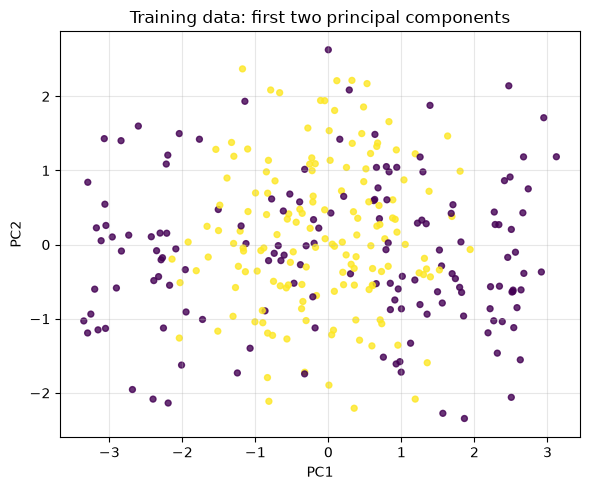

In [8]:
plt.figure(figsize=(6, 5))

plt.scatter(
    X_train_pca2[:, 0],
    X_train_pca2[:, 1],
    c=y_train,
    s=18,
    alpha=0.8
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Training data: first two principal components")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Classical logistic-regression baselines

To make the model comparisons as controlled as possible, logistic regression receives the
same angle-scaled 2D and 4D representations that are supplied to the corresponding VQCs.

In [9]:
logreg2 = LogisticRegression(
    max_iter=4000,
    random_state=SEED
)

logreg2.fit(X_train2, y_train)
pred_lr2 = logreg2.predict(X_test2)
acc_lr2 = accuracy_score(y_test, pred_lr2)


logreg4 = LogisticRegression(
    max_iter=4000,
    random_state=SEED
)

logreg4.fit(X_train4, y_train)
pred_lr4 = logreg4.predict(X_test4)
acc_lr4 = accuracy_score(y_test, pred_lr4)


print(f"Logistic regression 2D accuracy: {acc_lr2:.3f}")
print(f"Logistic regression 4D accuracy: {acc_lr4:.3f}")

Logistic regression 2D accuracy: 0.570
Logistic regression 4D accuracy: 0.700


## 9. Confusion matrices for the classical baselines

Saved: saved_plots/plot_2.png


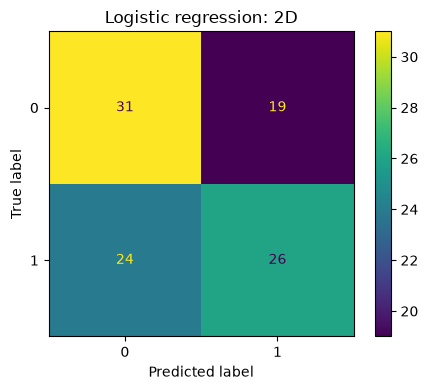

Saved: saved_plots/plot_3.png


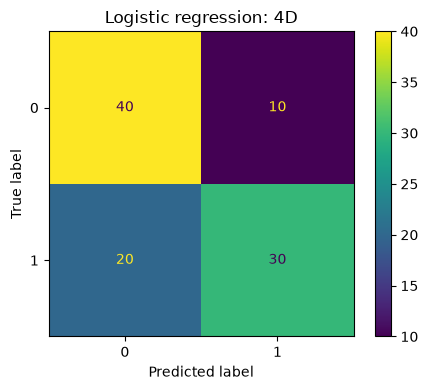

In [10]:
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_lr2)
).plot(ax=ax)

ax.set_title("Logistic regression: 2D")
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_lr4)
).plot(ax=ax)

ax.set_title("Logistic regression: 4D")
plt.tight_layout()
plt.show()

## 10. VQC helper functions

The key methodological point here is that the test set is **not used to choose the best random restart**.
The best restart is selected using the training objective returned by the optimizer.

In [11]:
def parity(z):
    # Binary class = parity of measured bitstring
    return bin(int(z)).count("1") % 2


def train_vqc_multistart(
    X_train,
    y_train,
    num_qubits,
    feature_map_reps,
    ansatz_reps,
    rotation_blocks,
    maxiter,
    n_restarts,
    seed=SEED,
    training_shots=TRAINING_SHOTS
):
    feature_map = zz_feature_map(
        feature_dimension=num_qubits,
        reps=feature_map_reps
    )

    ansatz = n_local(
        num_qubits=num_qubits,
        rotation_blocks=rotation_blocks,
        entanglement_blocks="cx",
        reps=ansatz_reps,
        entanglement="linear"
    )

    rng = np.random.default_rng(seed)

    best_model = None
    best_loss = np.inf
    restart_records = []

    for restart in range(n_restarts):
        initial_point = rng.uniform(
            -np.pi,
            np.pi,
            size=ansatz.num_parameters
        )

        # New sampler and optimizer for each restart.
        # Set the Qiskit algorithm RNG explicitly so SPSA is reproducible.
        restart_seed = seed + restart
        algorithm_globals.random_seed = restart_seed

        sampler_train = StatevectorSampler(
            default_shots=training_shots,
            seed=restart_seed
        )

        optimizer = SPSA(maxiter=maxiter)

        model = VQC(
            num_qubits=num_qubits,
            feature_map=feature_map,
            ansatz=ansatz,
            optimizer=optimizer,
            sampler=sampler_train,
            interpret=parity,
            output_shape=2,
            initial_point=initial_point
        )

        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        train_acc = accuracy_score(y_train, train_pred)

        fit_result = getattr(model, "fit_result", None)

        if fit_result is not None and getattr(fit_result, "fun", None) is not None:
            train_loss = float(fit_result.fun)
        else:
            # Fallback only if the installed version does not expose fit_result.fun
            train_loss = float(1.0 - train_acc)

        restart_records.append(
            {
                "restart": restart,
                "training_loss": train_loss,
                "training_accuracy": train_acc,
            }
        )

        print(
            f"restart {restart:02d} | "
            f"training loss={train_loss:.6f} | "
            f"training accuracy={train_acc:.3f}"
        )

        # IMPORTANT: selection uses training objective, NOT test accuracy.
        if train_loss < best_loss:
            best_loss = train_loss
            best_model = model

    restart_df = pd.DataFrame(restart_records)

    print("\nSelected restart using minimum training objective.")
    print("Best training loss:", best_loss)

    return best_model, restart_df

## 11. Train the 2-qubit VQC

In [12]:
best_vqc2, restarts2 = train_vqc_multistart(
    X_train=X_train2,
    y_train=y_train,
    num_qubits=2,
    feature_map_reps=2,
    ansatz_reps=4,
    rotation_blocks=["ry", "rz"],
    maxiter=600,
    n_restarts=8,
    seed=SEED
)

display(restarts2)

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 00 | training loss=0.977146 | training accuracy=0.603


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 01 | training loss=0.981562 | training accuracy=0.600


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 02 | training loss=1.001326 | training accuracy=0.593


... (5 outputs left out)

restart 05 | training loss=0.964215 | training accuracy=0.610


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 06 | training loss=0.978025 | training accuracy=0.610
restart 07 | training loss=0.973321 | training accuracy=0.613

Selected restart using minimum training objective.
Best training loss: 0.9642149596233907


,restart,training_loss,training_accuracy
0,0,0.977146,0.603333
1,1,0.981562,0.600000
2,2,1.001326,0.593333
3,3,0.972065,0.610000
4,4,0.979333,0.593333
5,5,0.964215,0.610000
6,6,0.978025,0.610000
7,7,0.973321,0.613333


## 12. Train the shallow 4-qubit VQC

In [13]:
best_vqc4, restarts4 = train_vqc_multistart(
    X_train=X_train4,
    y_train=y_train,
    num_qubits=4,
    feature_map_reps=1,
    ansatz_reps=1,
    rotation_blocks=["ry"],
    maxiter=1200,
    n_restarts=12,
    seed=SEED
)

display(restarts4)

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 00 | training loss=0.937503 | training accuracy=0.640


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 01 | training loss=0.947107 | training accuracy=0.607


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 02 | training loss=0.932748 | training accuracy=0.593


... (13 outputs left out)

restart 09 | training loss=0.933174 | training accuracy=0.597


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 10 | training loss=0.932431 | training accuracy=0.620
restart 11 | training loss=0.929285 | training accuracy=0.590

Selected restart using minimum training objective.
Best training loss: 0.9292850809541972


,restart,training_loss,training_accuracy
0,0,0.937503,0.640000
1,1,0.947107,0.606667
2,2,0.932748,0.593333
3,3,0.937300,0.630000
4,4,0.935265,0.600000
5,5,0.941852,0.626667
6,6,0.929885,0.593333
7,7,0.956238,0.556667
8,8,0.933367,0.620000
9,9,0.933174,0.596667


## 13. Exact noiseless statevector evaluation

This cell calculates class probabilities directly from the statevector and therefore introduces
**no finite-shot sampling noise**. These are the values that should be called the ideal/statevector
test accuracies.

In [14]:
def exact_statevector_probabilities(vqc_model, X):
    feature_map = vqc_model.feature_map
    ansatz = vqc_model.ansatz

    circuit = feature_map.compose(ansatz)

    input_params = list(feature_map.parameters)
    weight_params = list(ansatz.parameters)

    learned_weights = np.asarray(vqc_model.weights, dtype=float)

    all_class_probs = []

    for x in np.asarray(X):
        parameter_values = {}

        parameter_values.update(
            {
                parameter: value
                for parameter, value in zip(input_params, x)
            }
        )

        parameter_values.update(
            {
                parameter: value
                for parameter, value in zip(weight_params, learned_weights)
            }
        )

        bound_circuit = circuit.assign_parameters(
            parameter_values,
            inplace=False
        )

        state = Statevector.from_instruction(bound_circuit)
        basis_probs = state.probabilities()

        class_probs = np.zeros(2, dtype=float)

        for basis_index, probability in enumerate(basis_probs):
            class_probs[parity(basis_index)] += probability

        all_class_probs.append(class_probs)

    return np.asarray(all_class_probs)


def exact_statevector_predict(vqc_model, X):
    probabilities = exact_statevector_probabilities(
        vqc_model,
        X
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    return predictions, probabilities


pred_vqc2_ideal, prob_vqc2_ideal = exact_statevector_predict(
    best_vqc2,
    X_test2
)

pred_vqc4_ideal, prob_vqc4_ideal = exact_statevector_predict(
    best_vqc4,
    X_test4
)

acc_vqc2_ideal = accuracy_score(
    y_test,
    pred_vqc2_ideal
)

acc_vqc4_ideal = accuracy_score(
    y_test,
    pred_vqc4_ideal
)

print(f"2-qubit exact/statevector test accuracy: {acc_vqc2_ideal:.3f}")
print(f"4-qubit exact/statevector test accuracy: {acc_vqc4_ideal:.3f}")

2-qubit exact/statevector test accuracy: 0.630
4-qubit exact/statevector test accuracy: 0.610


## 14. Wilson 95% confidence intervals for held-out test accuracy

In [15]:
def wilson_ci_from_predictions(
    y_true,
    y_pred,
    alpha=0.05
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    n = len(y_true)
    correct = int(np.sum(y_true == y_pred))
    p_hat = correct / n

    z = norm.ppf(1 - alpha / 2)

    denominator = 1 + (z**2 / n)

    center = (
        p_hat + z**2 / (2 * n)
    ) / denominator

    half_width = (
        z
        * np.sqrt(
            p_hat * (1 - p_hat) / n
            + z**2 / (4 * n**2)
        )
        / denominator
    )

    return p_hat, center - half_width, center + half_width


deterministic_models = {
    "LogReg 2D": pred_lr2,
    "LogReg 4D": pred_lr4,
    "VQC 2-qubit ideal": pred_vqc2_ideal,
    "VQC 4-qubit ideal": pred_vqc4_ideal,
}

ci_rows = []

for model_name, predictions in deterministic_models.items():
    acc, low, high = wilson_ci_from_predictions(
        y_test,
        predictions
    )

    ci_rows.append(
        {
            "Model": model_name,
            "Accuracy": acc,
            "95% CI lower": low,
            "95% CI upper": high,
        }
    )

ci_table = pd.DataFrame(ci_rows)

display(ci_table)

,Model,Accuracy,95% CI lower,95% CI upper
0,LogReg 2D,0.57,0.472154,0.662667
1,LogReg 4D,0.70,0.604151,0.781051
2,VQC 2-qubit ideal,0.63,0.532205,0.718176
3,VQC 4-qubit ideal,0.61,0.512030,0.699831


## 15. Finite-shot evaluation

This is the long-running part of the notebook. For every shot count, each trained VQC is evaluated
10 times with seeds 1 through 10. The raw accuracies and predictions are retained.

In [16]:
def finite_shot_predictions(
    vqc_model,
    X,
    shots,
    seed
):
    feature_map = vqc_model.feature_map
    ansatz = vqc_model.ansatz

    circuit = feature_map.compose(ansatz)

    sampler = SamplerV2(
        default_shots=shots,
        seed=seed
    )

    qnn = SamplerQNN(
        circuit=circuit,
        input_params=list(feature_map.parameters),
        weight_params=list(ansatz.parameters),
        sampler=sampler,
        interpret=parity,
        output_shape=2
    )

    probabilities = qnn.forward(
        X,
        vqc_model.weights
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    return predictions, probabilities


def shot_sweep(
    vqc_model,
    X,
    y,
    shots_list=SHOTS_LIST,
    n_reps=N_SHOT_REPS,
    seed0=1
):
    summary = []
    raw_accuracies = {}
    raw_predictions = {}

    for shots in shots_list:
        accuracies = []
        predictions_for_shots = []

        for rep in range(n_reps):
            seed = seed0 + rep

            predictions, _ = finite_shot_predictions(
                vqc_model=vqc_model,
                X=X,
                shots=shots,
                seed=seed
            )

            accuracy = accuracy_score(
                y,
                predictions
            )

            accuracies.append(accuracy)
            predictions_for_shots.append(predictions)

        accuracies = np.asarray(
            accuracies,
            dtype=float
        )

        raw_accuracies[shots] = accuracies

        raw_predictions[shots] = np.asarray(
            predictions_for_shots,
            dtype=int
        )

        summary.append(
            {
                "shots": shots,
                "mean_accuracy": np.mean(accuracies),
                "std_accuracy": np.std(accuracies, ddof=1),
            }
        )

        print(
            f"{shots:4d} shots | "
            f"mean={np.mean(accuracies):.3f} | "
            f"SD={np.std(accuracies, ddof=1):.3f}"
        )

    return (
        pd.DataFrame(summary),
        raw_accuracies,
        raw_predictions,
    )


print("2-qubit finite-shot sweep")
shot_table2, accs2, preds2 = shot_sweep(
    best_vqc2,
    X_test2,
    y_test
)

print("\n4-qubit finite-shot sweep")
shot_table4, accs4, preds4 = shot_sweep(
    best_vqc4,
    X_test4,
    y_test
)

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


2-qubit finite-shot sweep


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler

  64 shots | mean=0.604 | SD=0.021


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler

 128 shots | mean=0.609 | SD=0.021


... (20 outputs left out)

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler

2048 shots | mean=0.609 | SD=0.006


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler

4096 shots | mean=0.610 | SD=0.000


## 16. Plot accuracy versus shot count

Saved: saved_plots/plot_4.png


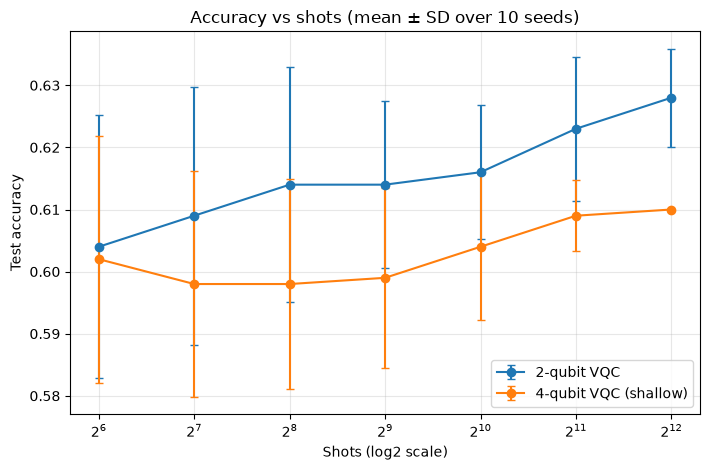

In [17]:
plt.figure(figsize=(7.2, 4.8))

plt.errorbar(
    shot_table2["shots"],
    shot_table2["mean_accuracy"],
    yerr=shot_table2["std_accuracy"],
    marker="o",
    capsize=3,
    label="2-qubit VQC"
)

plt.errorbar(
    shot_table4["shots"],
    shot_table4["mean_accuracy"],
    yerr=shot_table4["std_accuracy"],
    marker="o",
    capsize=3,
    label="4-qubit VQC (shallow)"
)

plt.xscale("log", base=2)
plt.xlabel("Shots (log2 scale)")
plt.ylabel("Test accuracy")
plt.title("Accuracy vs shots (mean ± SD over 10 seeds)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "accuracy_vs_shots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 17. 95% confidence intervals across the 10 finite-shot seeds

In [18]:
def mean_t_ci(values, alpha=0.05):
    values = np.asarray(values, dtype=float)

    n = len(values)
    mean = np.mean(values)
    sd = np.std(values, ddof=1)

    t_critical = t.ppf(
        1 - alpha / 2,
        df=n - 1
    )

    half_width = (
        t_critical
        * sd
        / np.sqrt(n)
    )

    return (
        mean,
        sd,
        mean - half_width,
        mean + half_width,
    )


finite_ci_rows = []

for model_name, acc_dict in [
    ("VQC 2-qubit", accs2),
    ("VQC 4-qubit", accs4),
]:
    for shots in SHOTS_LIST:
        mean, sd, low, high = mean_t_ci(
            acc_dict[shots]
        )

        finite_ci_rows.append(
            {
                "Model": model_name,
                "Shots": shots,
                "Mean accuracy": mean,
                "SD": sd,
                "95% CI lower": low,
                "95% CI upper": high,
            }
        )

finite_ci_table = pd.DataFrame(
    finite_ci_rows
)

display(finite_ci_table)

print("\n4096-shot results:")
display(
    finite_ci_table[
        finite_ci_table["Shots"] == 4096
    ]
)

,Model,Shots,Mean accuracy,SD,95% CI lower,95% CI upper
0,VQC 2-qubit,64,0.604,2.118700e-02,0.588844,0.619156
1,VQC 2-qubit,128,0.609,2.078995e-02,0.594128,0.623872
2,VQC 2-qubit,256,0.614,1.897367e-02,0.600427,0.627573
3,VQC 2-qubit,512,0.614,1.349897e-02,0.604343,0.623657
4,VQC 2-qubit,1024,0.616,1.074968e-02,0.608310,0.623690
5,VQC 2-qubit,2048,0.623,1.159502e-02,0.614705,0.631295
6,VQC 2-qubit,4096,0.628,7.888106e-03,0.622357,0.633643
7,VQC 4-qubit,64,0.602,1.988858e-02,0.587773,0.616227
8,VQC 4-qubit,128,0.598,1.813529e-02,0.585027,0.610973
9,VQC 4-qubit,256,0.598,1.686548e-02,0.585935,0.610065



4096-shot results:


,Model,Shots,Mean accuracy,SD,95% CI lower,95% CI upper
6,VQC 2-qubit,4096,0.628,7.888106e-03,0.622357,0.633643
13,VQC 4-qubit,4096,0.610,1.170278e-16,0.610000,0.610000


## 18. Exact McNemar tests for paired classifier predictions

These are the primary tests for comparing classifiers on the same held-out test observations.

In [19]:
def exact_mcnemar(
    y_true,
    pred_a,
    pred_b,
    name_a="Model A",
    name_b="Model B"
):
    y_true = np.asarray(y_true)
    pred_a = np.asarray(pred_a)
    pred_b = np.asarray(pred_b)

    correct_a = pred_a == y_true
    correct_b = pred_b == y_true

    # A correct, B wrong
    n10 = int(
        np.sum(
            correct_a & (~correct_b)
        )
    )

    # A wrong, B correct
    n01 = int(
        np.sum(
            (~correct_a) & correct_b
        )
    )

    discordant = n10 + n01

    if discordant == 0:
        p_value = 1.0
    else:
        p_value = binomtest(
            k=n10,
            n=discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue

    print(f"{name_a} correct / {name_b} wrong: {n10}")
    print(f"{name_a} wrong / {name_b} correct: {n01}")
    print(f"Exact McNemar p-value: {p_value:.6g}")

    return {
        "Comparison": f"{name_a} vs {name_b}",
        "A correct, B wrong": n10,
        "A wrong, B correct": n01,
        "p-value": p_value,
    }


mcnemar_results = []

print("2D matched comparison")
mcnemar_results.append(
    exact_mcnemar(
        y_test,
        pred_lr2,
        pred_vqc2_ideal,
        "LogReg 2D",
        "VQC 2-qubit ideal"
    )
)

print("\n4D matched comparison")
mcnemar_results.append(
    exact_mcnemar(
        y_test,
        pred_lr4,
        pred_vqc4_ideal,
        "LogReg 4D",
        "VQC 4-qubit ideal"
    )
)

mcnemar_table = pd.DataFrame(
    mcnemar_results
)

display(mcnemar_table)

2D matched comparison
LogReg 2D correct / VQC 2-qubit ideal wrong: 22
LogReg 2D wrong / VQC 2-qubit ideal correct: 28
Exact McNemar p-value: 0.479888

4D matched comparison
LogReg 4D correct / VQC 4-qubit ideal wrong: 24
LogReg 4D wrong / VQC 4-qubit ideal correct: 15
Exact McNemar p-value: 0.199591


,Comparison,"A correct, B wrong","A wrong, B correct",p-value
0,LogReg 2D vs VQC 2-qubit ideal,22,28,0.479888
1,LogReg 4D vs VQC 4-qubit ideal,24,15,0.199591


## 19. Wilcoxon tests for paired finite-shot accuracy

In [20]:
def safe_wilcoxon(
    values_a,
    values_b,
    alternative="two-sided"
):
    values_a = np.asarray(values_a, dtype=float)
    values_b = np.asarray(values_b, dtype=float)

    if np.allclose(values_a, values_b):
        return 0.0, 1.0

    result = wilcoxon(
        values_a,
        values_b,
        alternative=alternative
    )

    return float(result.statistic), float(result.pvalue)


# 2-qubit vs 4-qubit at 4096 shots, paired by seed
w_stat_4096, w_p_4096 = safe_wilcoxon(
    accs2[4096],
    accs4[4096]
)

print(
    "2-qubit vs 4-qubit at 4096 shots:"
)
print(
    f"Wilcoxon statistic={w_stat_4096:.4f}, "
    f"p={w_p_4096:.6g}"
)


# Endpoint test: 64 vs 4096 shots for each VQC
w_stat_2q, w_p_2q = safe_wilcoxon(
    accs2[64],
    accs2[4096]
)

w_stat_4q, w_p_4q = safe_wilcoxon(
    accs4[64],
    accs4[4096]
)

print("\n2-qubit, 64 vs 4096 shots:")
print(
    f"Wilcoxon statistic={w_stat_2q:.4f}, "
    f"p={w_p_2q:.6g}"
)

print("\n4-qubit, 64 vs 4096 shots:")
print(
    f"Wilcoxon statistic={w_stat_4q:.4f}, "
    f"p={w_p_4q:.6g}"
)

2-qubit vs 4-qubit at 4096 shots:
Wilcoxon statistic=0.0000, p=0.00195312

2-qubit, 64 vs 4096 shots:
Wilcoxon statistic=1.0000, p=0.03125

4-qubit, 64 vs 4096 shots:
Wilcoxon statistic=12.0000, p=0.253906


## 20. Friedman repeated-measures test across all shot counts

In [21]:
def safe_friedman(acc_dict, shots_list=SHOTS_LIST):
    arrays = [
        np.asarray(
            acc_dict[shots],
            dtype=float
        )
        for shots in shots_list
    ]

    stacked = np.vstack(arrays)

    # If absolutely every value is identical, there is no shot effect.
    if np.allclose(stacked, stacked.flat[0]):
        return 0.0, 1.0

    result = friedmanchisquare(
        *arrays
    )

    return (
        float(result.statistic),
        float(result.pvalue),
    )


friedman_stat2, friedman_p2 = safe_friedman(
    accs2
)

friedman_stat4, friedman_p4 = safe_friedman(
    accs4
)

print(
    f"2-qubit Friedman: "
    f"statistic={friedman_stat2:.4f}, "
    f"p={friedman_p2:.6g}"
)

print(
    f"4-qubit Friedman: "
    f"statistic={friedman_stat4:.4f}, "
    f"p={friedman_p4:.6g}"
)

2-qubit Friedman: statistic=12.6818, p=0.0483763
4-qubit Friedman: statistic=8.8080, p=0.184667


## 21. Circuit-complexity metrics

In [22]:
def circuit_complexity(vqc_model):
    feature_map = vqc_model.feature_map
    ansatz = vqc_model.ansatz

    circuit = feature_map.compose(ansatz)

    # Decompose high-level library instructions
    flat = circuit.decompose(reps=10)

    # Superconducting-style basis used in the manuscript
    transpiled_circuit = transpile(
        circuit,
        basis_gates=["rz", "sx", "x", "cx"],
        optimization_level=0
    )

    return {
        "Flat depth": int(flat.depth()),
        "Flat CX": int(
            flat.count_ops().get("cx", 0)
        ),
        "Transpiled depth": int(
            transpiled_circuit.depth()
        ),
        "Transpiled CX": int(
            transpiled_circuit.count_ops().get("cx", 0)
        ),
    }


complexity2 = circuit_complexity(
    best_vqc2
)

complexity4 = circuit_complexity(
    best_vqc4
)

complexity_table = pd.DataFrame(
    [
        {
            "Model": "2-qubit VQC",
            **complexity2,
        },
        {
            "Model": "4-qubit VQC (shallow)",
            **complexity4,
        },
    ]
)

display(complexity_table)

,Model,Flat depth,Flat CX,Transpiled depth,Transpiled CX
0,2-qubit VQC,24,8,48,8
1,4-qubit VQC (shallow),21,15,31,15


## 22. Publication-ready VQC summary table

In [23]:
def get_shot_summary_row(
    finite_ci_table,
    model_name,
    shots=4096
):
    row = finite_ci_table[
        (finite_ci_table["Model"] == model_name)
        & (finite_ci_table["Shots"] == shots)
    ].iloc[0]

    return row


row2 = get_shot_summary_row(
    finite_ci_table,
    "VQC 2-qubit",
    4096
)

row4 = get_shot_summary_row(
    finite_ci_table,
    "VQC 4-qubit",
    4096
)


_, ideal2_low, ideal2_high = wilson_ci_from_predictions(
    y_test,
    pred_vqc2_ideal
)

_, ideal4_low, ideal4_high = wilson_ci_from_predictions(
    y_test,
    pred_vqc4_ideal
)


publication_table = pd.DataFrame(
    [
        {
            "Model": "2-qubit VQC",
            "Ideal accuracy": acc_vqc2_ideal,
            "Ideal 95% CI": f"[{ideal2_low:.3f}, {ideal2_high:.3f}]",
            "4096-shot mean": row2["Mean accuracy"],
            "4096-shot SD": row2["SD"],
            "4096-shot 95% CI": (
                f"[{row2['95% CI lower']:.3f}, "
                f"{row2['95% CI upper']:.3f}]"
            ),
            **complexity2,
        },
        {
            "Model": "4-qubit VQC (shallow)",
            "Ideal accuracy": acc_vqc4_ideal,
            "Ideal 95% CI": f"[{ideal4_low:.3f}, {ideal4_high:.3f}]",
            "4096-shot mean": row4["Mean accuracy"],
            "4096-shot SD": row4["SD"],
            "4096-shot 95% CI": (
                f"[{row4['95% CI lower']:.3f}, "
                f"{row4['95% CI upper']:.3f}]"
            ),
            **complexity4,
        },
    ]
)

display(publication_table)

,Model,Ideal accuracy,Ideal 95% CI,4096-shot mean,4096-shot SD,4096-shot 95% CI,Flat depth,Flat CX,Transpiled depth,Transpiled CX
0,2-qubit VQC,0.63,"[0.532, 0.718]",0.628,7.888106e-03,"[0.622, 0.634]",24,8,48,8
1,4-qubit VQC (shallow),0.61,"[0.512, 0.700]",0.610,1.170278e-16,"[0.610, 0.610]",21,15,31,15


## 23. Collect all statistical tests into one table

In [24]:
statistical_tests = pd.DataFrame(
    [
        {
            "Test": "Exact McNemar",
            "Comparison": "LogReg 2D vs VQC 2-qubit ideal",
            "Statistic": np.nan,
            "p-value": mcnemar_table.iloc[0]["p-value"],
        },
        {
            "Test": "Exact McNemar",
            "Comparison": "LogReg 4D vs VQC 4-qubit ideal",
            "Statistic": np.nan,
            "p-value": mcnemar_table.iloc[1]["p-value"],
        },
        {
            "Test": "Wilcoxon signed-rank",
            "Comparison": "2-qubit vs 4-qubit at 4096 shots",
            "Statistic": w_stat_4096,
            "p-value": w_p_4096,
        },
        {
            "Test": "Wilcoxon signed-rank",
            "Comparison": "2-qubit: 64 vs 4096 shots",
            "Statistic": w_stat_2q,
            "p-value": w_p_2q,
        },
        {
            "Test": "Wilcoxon signed-rank",
            "Comparison": "4-qubit: 64 vs 4096 shots",
            "Statistic": w_stat_4q,
            "p-value": w_p_4q,
        },
        {
            "Test": "Friedman",
            "Comparison": "2-qubit accuracy across all shot counts",
            "Statistic": friedman_stat2,
            "p-value": friedman_p2,
        },
        {
            "Test": "Friedman",
            "Comparison": "4-qubit accuracy across all shot counts",
            "Statistic": friedman_stat4,
            "p-value": friedman_p4,
        },
    ]
)

statistical_tests["Significant at 0.05"] = (
    statistical_tests["p-value"] < 0.05
)

display(statistical_tests)

,Test,Comparison,Statistic,p-value,Significant at 0.05
0,Exact McNemar,LogReg 2D vs VQC 2-qubit ideal,NaN,0.479888,False
1,Exact McNemar,LogReg 4D vs VQC 4-qubit ideal,NaN,0.199591,False
2,Wilcoxon signed-rank,2-qubit vs 4-qubit at 4096 shots,0.000000,0.001953,True
3,Wilcoxon signed-rank,2-qubit: 64 vs 4096 shots,1.000000,0.031250,True
4,Wilcoxon signed-rank,4-qubit: 64 vs 4096 shots,12.000000,0.253906,False
5,Friedman,2-qubit accuracy across all shot counts,12.681818,0.048376,True
6,Friedman,4-qubit accuracy across all shot counts,8.808000,0.184667,False


## 24. Save tables and raw finite-shot results

In [25]:
# Combine shot tables for saving
shot_table2_save = shot_table2.copy()
shot_table2_save.insert(
    0,
    "Model",
    "2-qubit VQC"
)

shot_table4_save = shot_table4.copy()
shot_table4_save.insert(
    0,
    "Model",
    "4-qubit VQC"
)

shot_summary_all = pd.concat(
    [
        shot_table2_save,
        shot_table4_save
    ],
    ignore_index=True
)

# Raw finite-shot accuracy table
raw_rows = []

for model_name, acc_dict in [
    ("2-qubit VQC", accs2),
    ("4-qubit VQC", accs4),
]:
    for shots in SHOTS_LIST:
        for rep, accuracy in enumerate(
            acc_dict[shots],
            start=1
        ):
            raw_rows.append(
                {
                    "Model": model_name,
                    "Shots": shots,
                    "Seed": rep,
                    "Accuracy": accuracy,
                }
            )

raw_shot_accuracies = pd.DataFrame(
    raw_rows
)

ci_table.to_csv(
    "deterministic_accuracy_confidence_intervals.csv",
    index=False
)

finite_ci_table.to_csv(
    "finite_shot_confidence_intervals.csv",
    index=False
)

shot_summary_all.to_csv(
    "shot_sweep_summary.csv",
    index=False
)

raw_shot_accuracies.to_csv(
    "raw_shot_accuracies.csv",
    index=False
)

mcnemar_table.to_csv(
    "mcnemar_tests.csv",
    index=False
)

statistical_tests.to_csv(
    "statistical_tests.csv",
    index=False
)

complexity_table.to_csv(
    "circuit_complexity.csv",
    index=False
)

publication_table.to_csv(
    "publication_vqc_summary.csv",
    index=False
)

print("Saved all result tables to CSV files.")

Saved all result tables to CSV files.


## 25. Interpreting the original statistical output

Wilson intervals describe accuracy on the held-out sample. Exact McNemar tests compare paired predictions on the shared primary holdout. For the five PNN comparisons, apply Holm adjustment as reported in the revised manuscript. The original implementation can show nominal p-values.

Matched shot-seed tests quantify sampling variation conditional on the trained circuits and test set. Mesh perturbation draws quantify conditional setting uncertainty for a trained optical model. Independently regenerated datasets are the units for comparing generalization. Neither optical nor quantum simulation runtime measures hardware latency.


# 26. Photonic Neural Network Extension: 4-Mode MZI-Mesh-Inspired Classifier

This section adds a **numerical architecture-level photonic neural network (PNN) simulation** to the same benchmark.

It deliberately does **not** claim to be a fabricated silicon-photonic device or a full electromagnetic device simulation.

### What is modeled
- The same **4D PCA representation** already used in the 4-qubit comparison.
- Four optical input modes.
- A compact 4×4 interferometric mesh containing **6 MZI-like two-mode transformations**.
- Square-law photodetection: \(I_k = |E_k|^2\).
- Balanced differential readout for binary classification.
- Controlled perturbation of MZI splitting-angle and phase parameters to approximate calibration/fabrication/phase-setting error.

### What is not modeled
- Waveguide geometry.
- Full electromagnetic propagation.
- Device-specific insertion loss.
- Detector responsivity.
- DAC/ADC timing.
- Foundry-specific phase-shifter drift.
- Actual hardware wall-clock latency.

The PNN accuracy simulation and the hardware-latency model must therefore remain separate in the manuscript.

## 26.1 Imports and checks

In [26]:
from scipy.optimize import minimize
from scipy.stats import friedmanchisquare, wilcoxon, binomtest, norm, t
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# The PNN extension uses the preprocessing already completed earlier.
required_variables = [
    "X_train_pca4",
    "X_test_pca4",
    "y_train",
    "y_test",
    "pred_lr4",
]

missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the notebook from the beginning through the 4D PCA and "
        "logistic-regression sections first. Missing variables: "
        + ", ".join(missing_variables)
    )

print("PNN prerequisite variables are available.")
print("Training shape:", X_train_pca4.shape)
print("Test shape:", X_test_pca4.shape)

PNN prerequisite variables are available.
Training shape: (300, 4)
Test shape: (100, 4)


## 26.2 Photonic input encoding

The four PCA components are converted to bounded optical amplitudes.

A scaler is fitted **only on the training data**:

\[
x_j \rightarrow [-1,1].
\]

The amplitudes are then divided by \(\sqrt{4}=2\), so that an input whose four components all have magnitude one after scaling has total normalized optical power no larger than one:

\[
\sum_{j=1}^{4}|E_j|^2 \le 1.
\]

Negative real amplitudes can be interpreted as a \(\pi\)-phase reversal. This preserves the sign information in the PCA coordinates while keeping the representation compatible with coherent interference.

In [27]:
pnn_input_scaler = MinMaxScaler(
    feature_range=(-1, 1),
    clip=True
)

X_train_pnn = pnn_input_scaler.fit_transform(
    X_train_pca4
)

X_test_pnn = pnn_input_scaler.transform(
    X_test_pca4
)

# Four optical modes -> divide by sqrt(4)=2.
X_train_pnn = X_train_pnn / 2.0
X_test_pnn = X_test_pnn / 2.0

train_power = np.sum(
    np.abs(X_train_pnn)**2,
    axis=1
)

test_power = np.sum(
    np.abs(X_test_pnn)**2,
    axis=1
)

print("PNN training input shape:", X_train_pnn.shape)
print("PNN test input shape:", X_test_pnn.shape)
print("Maximum normalized training input power:", train_power.max())
print("Maximum normalized test input power:", test_power.max())

PNN training input shape: (300, 4)
PNN test input shape: (100, 4)
Maximum normalized training input power: 0.6058147245748797
Maximum normalized test input power: 0.5039078039042519


## 26.3 Four-mode MZI mesh

Each two-mode interferometric element is represented by

\[
M(\theta,\phi)=
\begin{bmatrix}
e^{i\phi}\cos\theta & \sin\theta \\
-\sin\theta & e^{-i\phi}\cos\theta
\end{bmatrix}.
\]

For four modes, the mesh uses six pairwise transformations, consistent with the \(N(N-1)/2=6\) two-mode mixing stages required for a generic four-mode interferometric decomposition.

The optical field transformation is

\[
\mathbf E_{\mathrm{out}}
=
U(\boldsymbol{\theta},\boldsymbol{\phi})
\mathbf E_{\mathrm{in}}.
\]

Photodetection produces

\[
I_k = |E_{\mathrm{out},k}|^2.
\]

A balanced binary readout is then defined by

\[
s =
g\left[
(I_2+I_3)-(I_0+I_1)
\right]+b,
\]

with class 1 predicted when \(s\ge 0\).

Only the interferometer settings plus the final gain/threshold are trained. This is intentionally a small hardware-motivated classifier rather than a conventional deep digital neural network.

In [28]:
# Six two-mode transformations for a 4-mode mesh.
MZI_PAIRS = [
    (0, 1),
    (2, 3),
    (1, 2),
    (0, 1),
    (2, 3),
    (1, 2),
]

N_PNN_MODES = 4
N_MZIS = len(MZI_PAIRS)


def mzi_block(theta, phi):
    c = np.cos(theta)
    s = np.sin(theta)

    return np.array(
        [
            [np.exp(1j * phi) * c, s],
            [-s, np.exp(-1j * phi) * c],
        ],
        dtype=complex
    )


def mzi_mesh_matrix(
    thetas,
    phis,
    n_modes=N_PNN_MODES
):
    U = np.eye(
        n_modes,
        dtype=complex
    )

    for (i, j), theta, phi in zip(
        MZI_PAIRS,
        thetas,
        phis
    ):
        G = np.eye(
            n_modes,
            dtype=complex
        )

        G[np.ix_([i, j], [i, j])] = (
            mzi_block(theta, phi)
        )

        U = G @ U

    return U


def unpack_pnn_params(params):
    params = np.asarray(
        params,
        dtype=float
    )

    thetas = params[:N_MZIS]

    phis = params[
        N_MZIS:2 * N_MZIS
    ]

    gain = params[-2]
    bias = params[-1]

    return (
        thetas,
        phis,
        gain,
        bias
    )


def pnn_forward(
    params,
    X
):
    thetas, phis, gain, bias = (
        unpack_pnn_params(params)
    )

    U = mzi_mesh_matrix(
        thetas,
        phis
    )

    # Each row of X is one four-mode optical input.
    fields = (
        U @ np.asarray(X).T
    ).T

    intensities = (
        np.abs(fields)**2
    )

    differential_intensity = (
        np.sum(
            intensities[:, 2:4],
            axis=1
        )
        -
        np.sum(
            intensities[:, 0:2],
            axis=1
        )
    )

    scores = (
        gain
        * differential_intensity
        + bias
    )

    return (
        scores,
        intensities,
        U
    )


def pnn_predict(
    params,
    X
):
    scores, _, _ = pnn_forward(
        params,
        X
    )

    return (
        scores >= 0
    ).astype(int)


def pnn_cross_entropy(
    params,
    X,
    y,
    l2_gain=1e-4
):
    scores, _, _ = pnn_forward(
        params,
        X
    )

    y = np.asarray(
        y,
        dtype=float
    )

    # Stable binary cross-entropy:
    # log(1 + exp(score)) - y*score
    loss = np.mean(
        np.logaddexp(
            0.0,
            scores
        )
        - y * scores
    )

    # Very small penalty prevents an unnecessarily huge
    # electronic readout gain.
    gain = params[-2]

    return (
        loss
        + l2_gain * gain**2
    )

## 26.4 Train the ideal PNN

Multiple random initializations are used because the interferometric parameterization is nonconvex.

The **test set is not used to choose the best restart**. The selected model is the restart with the lowest training cross-entropy.

In [29]:
PNN_SEED = 7
PNN_RESTARTS = 20
PNN_MAXITER = 800


def train_pnn_multistart(
    X_train,
    y_train,
    n_restarts=PNN_RESTARTS,
    maxiter=PNN_MAXITER,
    seed=PNN_SEED
):
    rng = np.random.default_rng(
        seed
    )

    # 6 theta + 6 phi + gain + bias = 14 parameters
    bounds = (
        [(-np.pi, np.pi)] * (2 * N_MZIS)
        + [(-20.0, 20.0)]
        + [(-10.0, 10.0)]
    )

    best_result = None
    records = []

    for restart in range(
        n_restarts
    ):
        initial_point = np.concatenate(
            [
                rng.uniform(
                    -np.pi,
                    np.pi,
                    size=2 * N_MZIS
                ),
                rng.uniform(
                    -1.0,
                    1.0,
                    size=1
                ),
                np.array([0.0])
            ]
        )

        result = minimize(
            pnn_cross_entropy,
            initial_point,
            args=(X_train, y_train),
            method="L-BFGS-B",
            bounds=bounds,
            options={
                "maxiter": maxiter,
                "ftol": 1e-10,
                "gtol": 1e-7,
            }
        )

        train_pred = pnn_predict(
            result.x,
            X_train
        )

        train_acc = accuracy_score(
            y_train,
            train_pred
        )

        records.append(
            {
                "restart": restart,
                "training_loss": result.fun,
                "training_accuracy": train_acc,
                "optimizer_success": result.success,
                "iterations": result.nit,
            }
        )

        print(
            f"restart {restart:02d} | "
            f"loss={result.fun:.6f} | "
            f"train accuracy={train_acc:.3f} | "
            f"success={result.success}"
        )

        if (
            best_result is None
            or result.fun < best_result.fun
        ):
            best_result = result

    restart_table = pd.DataFrame(
        records
    )

    return (
        best_result,
        restart_table
    )


best_pnn_result, pnn_restart_table = (
    train_pnn_multistart(
        X_train_pnn,
        y_train
    )
)

best_pnn_params = (
    best_pnn_result.x
)

print(
    "\nSelected PNN training loss:",
    best_pnn_result.fun
)

display(
    pnn_restart_table.sort_values(
        "training_loss"
    ).head(10)
)

restart 00 | loss=0.324172 | train accuracy=0.883 | success=True
restart 01 | loss=0.324172 | train accuracy=0.883 | success=True
restart 02 | loss=0.324172 | train accuracy=0.883 | success=True
restart 03 | loss=0.338508 | train accuracy=0.873 | success=True
restart 04 | loss=0.324172 | train accuracy=0.883 | success=True
restart 05 | loss=0.338508 | train accuracy=0.873 | success=True
restart 06 | loss=0.359684 | train accuracy=0.860 | success=True
restart 07 | loss=0.324172 | train accuracy=0.883 | success=True
restart 08 | loss=0.324172 | train accuracy=0.883 | success=True
restart 09 | loss=0.324172 | train accuracy=0.883 | success=True
restart 10 | loss=0.338508 | train accuracy=0.873 | success=True
restart 11 | loss=0.338508 | train accuracy=0.873 | success=True
restart 12 | loss=0.359684 | train accuracy=0.860 | success=True
restart 13 | loss=0.324172 | train accuracy=0.883 | success=True
restart 14 | loss=0.324172 | train accuracy=0.883 | success=True
restart 15 | loss=0.32417

,restart,training_loss,training_accuracy,optimizer_success,iterations
15,15,0.324172,0.883333,True,51
0,0,0.324172,0.883333,True,59
19,19,0.324172,0.883333,True,38
8,8,0.324172,0.883333,True,50
14,14,0.324172,0.883333,True,51
16,16,0.324172,0.883333,True,62
1,1,0.324172,0.883333,True,51
9,9,0.324172,0.883333,True,60
13,13,0.324172,0.883333,True,115
4,4,0.324172,0.883333,True,82


## 26.5 Ideal PNN test accuracy and 95% Wilson confidence interval

In [30]:
pred_pnn_ideal = pnn_predict(
    best_pnn_params,
    X_test_pnn
)

pnn_acc_ideal = accuracy_score(
    y_test,
    pred_pnn_ideal
)


def pnn_wilson_ci(
    y_true,
    y_pred,
    alpha=0.05
):
    y_true = np.asarray(
        y_true
    )

    y_pred = np.asarray(
        y_pred
    )

    n = len(y_true)

    correct = int(
        np.sum(
            y_true == y_pred
        )
    )

    p_hat = correct / n

    z = norm.ppf(
        1 - alpha / 2
    )

    denominator = (
        1 + z**2 / n
    )

    center = (
        p_hat
        + z**2 / (2 * n)
    ) / denominator

    half_width = (
        z
        * np.sqrt(
            p_hat * (1 - p_hat) / n
            + z**2 / (4 * n**2)
        )
        / denominator
    )

    return (
        p_hat,
        center - half_width,
        center + half_width
    )


(
    pnn_acc_ideal,
    pnn_ci_low,
    pnn_ci_high
) = pnn_wilson_ci(
    y_test,
    pred_pnn_ideal
)

print(
    f"Ideal MZI-mesh-inspired PNN accuracy: "
    f"{pnn_acc_ideal:.3f}"
)

print(
    f"95% Wilson CI: "
    f"[{pnn_ci_low:.3f}, "
    f"{pnn_ci_high:.3f}]"
)

print(
    "Correct predictions:",
    int(
        np.sum(
            y_test
            == pred_pnn_ideal
        )
    ),
    "out of",
    len(y_test)
)

Ideal MZI-mesh-inspired PNN accuracy: 0.870
95% Wilson CI: [0.790, 0.922]
Correct predictions: 87 out of 100


## 26.6 PNN confusion matrix

Saved: saved_plots/plot_5.png


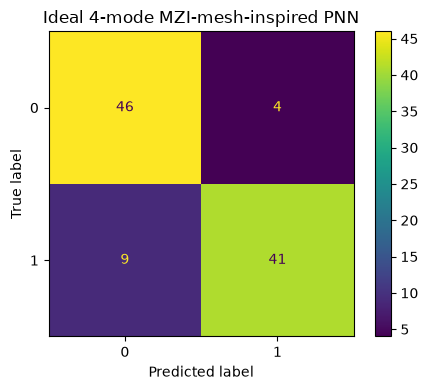

In [31]:
fig, ax = plt.subplots(
    figsize=(5, 4)
)

ConfusionMatrixDisplay(
    confusion_matrix(
        y_test,
        pred_pnn_ideal
    )
).plot(
    ax=ax
)

ax.set_title(
    "Ideal 4-mode MZI-mesh-inspired PNN"
)

plt.tight_layout()

plt.savefig(
    "pnn_ideal_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 26.7 Controlled photonic mesh-parameter perturbation

To test robustness, both the trained MZI splitting-angle parameters and internal phase parameters are perturbed:

\[
\theta_m'
=
\theta_m
+
\epsilon_{\theta,m},
\]

\[
\phi_m'
=
\phi_m
+
\epsilon_{\phi,m},
\]

with

\[
\epsilon_{\theta,m},
\epsilon_{\phi,m}
\sim
\mathcal N(0,\sigma_{\mathrm{mesh}}^2).
\]

The tested RMS perturbation levels are

\[
\sigma_{\mathrm{mesh}}
=
0,\;
0.01,\;
0.02,\;
0.05,\;
0.10,\;
0.20,\;
0.30
\text{ radians}.
\]

Each nonideal condition is repeated over 50 matched random seeds.

**Interpretation:** this is a generic architecture-level perturbation model for phase-setting, coupling/weight-setting, calibration, and fabrication uncertainty. It is **not** calibrated to a particular photonic foundry or chip.

In [32]:
PNN_NOISE_SIGMAS = [
    0.00,
    0.01,
    0.02,
    0.05,
    0.10,
    0.20,
    0.30,
]

PNN_NOISE_REPS = 50
PNN_NOISE_SEED0 = 1000


def pnn_predict_with_mesh_noise(
    params,
    X,
    sigma_mesh,
    seed
):
    (
        thetas,
        phis,
        gain,
        bias
    ) = unpack_pnn_params(
        params
    )

    rng = np.random.default_rng(
        seed
    )

    noisy_thetas = (
        thetas
        + rng.normal(
            0.0,
            sigma_mesh,
            size=thetas.shape
        )
    )

    noisy_phis = (
        phis
        + rng.normal(
            0.0,
            sigma_mesh,
            size=phis.shape
        )
    )

    noisy_params = np.concatenate(
        [
            noisy_thetas,
            noisy_phis,
            [gain, bias],
        ]
    )

    return pnn_predict(
        noisy_params,
        X
    )


def run_pnn_noise_sweep(
    params,
    X,
    y,
    sigmas=PNN_NOISE_SIGMAS,
    n_reps=PNN_NOISE_REPS,
    seed0=PNN_NOISE_SEED0
):
    raw_accuracies = {}
    raw_predictions = {}
    rows = []

    for sigma_mesh in sigmas:
        accuracies = []
        predictions = []

        for rep in range(
            n_reps
        ):
            seed = (
                seed0 + rep
            )

            pred = (
                pnn_predict_with_mesh_noise(
                    params=params,
                    X=X,
                    sigma_mesh=sigma_mesh,
                    seed=seed
                )
            )

            acc = accuracy_score(
                y,
                pred
            )

            accuracies.append(
                acc
            )

            predictions.append(
                pred
            )

        accuracies = np.asarray(
            accuracies,
            dtype=float
        )

        raw_accuracies[
            sigma_mesh
        ] = accuracies

        raw_predictions[
            sigma_mesh
        ] = np.asarray(
            predictions,
            dtype=int
        )

        rows.append(
            {
                "sigma_rad": sigma_mesh,
                "sigma_deg": np.degrees(
                    sigma_mesh
                ),
                "mean_accuracy": np.mean(
                    accuracies
                ),
                "sd_accuracy": np.std(
                    accuracies,
                    ddof=1
                ),
            }
        )

        print(
            f"sigma={sigma_mesh:.3f} rad "
            f"({np.degrees(sigma_mesh):.2f} deg) | "
            f"mean={np.mean(accuracies):.3f} | "
            f"SD={np.std(accuracies, ddof=1):.3f}"
        )

    return (
        pd.DataFrame(rows),
        raw_accuracies,
        raw_predictions,
    )


(
    pnn_noise_table,
    pnn_noise_accs,
    pnn_noise_preds
) = run_pnn_noise_sweep(
    best_pnn_params,
    X_test_pnn,
    y_test
)

display(
    pnn_noise_table
)

sigma=0.000 rad (0.00 deg) | mean=0.870 | SD=0.000
sigma=0.010 rad (0.57 deg) | mean=0.864 | SD=0.011
sigma=0.020 rad (1.15 deg) | mean=0.849 | SD=0.021
sigma=0.050 rad (2.86 deg) | mean=0.828 | SD=0.031
sigma=0.100 rad (5.73 deg) | mean=0.808 | SD=0.038
sigma=0.200 rad (11.46 deg) | mean=0.752 | SD=0.067
sigma=0.300 rad (17.19 deg) | mean=0.697 | SD=0.092


,sigma_rad,sigma_deg,mean_accuracy,sd_accuracy
0,0.00,0.000000,0.8700,1.121495e-16
1,0.01,0.572958,0.8638,1.104536e-02
2,0.02,1.145916,0.8486,2.147709e-02
3,0.05,2.864789,0.8284,3.092849e-02
4,0.10,5.729578,0.8080,3.849198e-02
5,0.20,11.459156,0.7522,6.686233e-02
6,0.30,17.188734,0.6970,9.205699e-02


## 26.8 Mean ± SD and 95% confidence interval at each PNN noise level

In [33]:
def pnn_mean_t_ci(
    values,
    alpha=0.05
):
    values = np.asarray(
        values,
        dtype=float
    )

    n = len(values)

    mean = np.mean(
        values
    )

    sd = np.std(
        values,
        ddof=1
    )

    # At sigma=0 the ideal prediction is deterministic,
    # so all Monte Carlo entries are identical.
    if np.isclose(
        sd,
        0.0
    ):
        return (
            mean,
            sd,
            mean,
            mean
        )

    t_critical = t.ppf(
        1 - alpha / 2,
        df=n - 1
    )

    half_width = (
        t_critical
        * sd
        / np.sqrt(n)
    )

    return (
        mean,
        sd,
        mean - half_width,
        mean + half_width
    )


pnn_noise_ci_rows = []

for sigma_mesh in (
    PNN_NOISE_SIGMAS
):
    (
        mean,
        sd,
        low,
        high
    ) = pnn_mean_t_ci(
        pnn_noise_accs[
            sigma_mesh
        ]
    )

    pnn_noise_ci_rows.append(
        {
            "sigma_rad": sigma_mesh,
            "sigma_deg": np.degrees(
                sigma_mesh
            ),
            "mean_accuracy": mean,
            "SD": sd,
            "95% CI lower": low,
            "95% CI upper": high,
            "mean_accuracy_drop_from_ideal": (
                pnn_acc_ideal - mean
            ),
        }
    )


pnn_noise_ci_table = pd.DataFrame(
    pnn_noise_ci_rows
)

display(
    pnn_noise_ci_table
)

,sigma_rad,sigma_deg,mean_accuracy,SD,95% CI lower,95% CI upper,mean_accuracy_drop_from_ideal
0,0.00,0.000000,0.8700,1.121495e-16,0.870000,0.870000,1.110223e-16
1,0.01,0.572958,0.8638,1.104536e-02,0.860661,0.866939,6.200000e-03
2,0.02,1.145916,0.8486,2.147709e-02,0.842496,0.854704,2.140000e-02
3,0.05,2.864789,0.8284,3.092849e-02,0.819610,0.837190,4.160000e-02
4,0.10,5.729578,0.8080,3.849198e-02,0.797061,0.818939,6.200000e-02
5,0.20,11.459156,0.7522,6.686233e-02,0.733198,0.771202,1.178000e-01
6,0.30,17.188734,0.6970,9.205699e-02,0.670838,0.723162,1.730000e-01


## 26.9 Plot PNN accuracy versus mesh-parameter error

Saved: saved_plots/plot_6.png


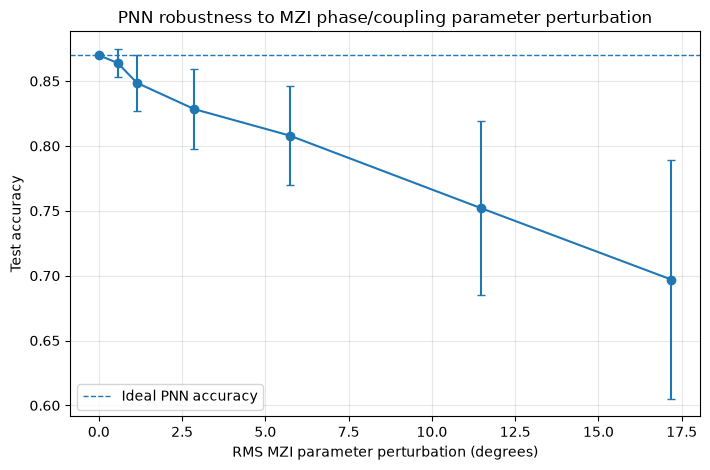

In [34]:
plt.figure(
    figsize=(7.2, 4.8)
)

plt.errorbar(
    pnn_noise_ci_table["sigma_deg"],
    pnn_noise_ci_table["mean_accuracy"],
    yerr=pnn_noise_ci_table["SD"],
    marker="o",
    capsize=3
)

plt.axhline(
    pnn_acc_ideal,
    linestyle="--",
    linewidth=1,
    label="Ideal PNN accuracy"
)

plt.xlabel(
    "RMS MZI parameter perturbation (degrees)"
)

plt.ylabel(
    "Test accuracy"
)

plt.title(
    "PNN robustness to MZI phase/coupling parameter perturbation"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "pnn_accuracy_vs_mesh_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 26.10 Statistical test for the photonic-noise effect

The 50 random seeds are matched across all noise levels, so the noise sweep is treated as a repeated-measures Monte Carlo experiment.

1. **Friedman test:** tests whether the accuracy distributions differ somewhere across the seven noise levels.
2. **Post-hoc Wilcoxon signed-rank tests:** compare the ideal condition (\(\sigma=0\)) with each nonzero perturbation level.
3. **Holm correction:** controls family-wise error across the six post-hoc comparisons.

These p-values quantify behavior under the **chosen Monte Carlo perturbation model**. They should not be presented as measurements of a particular fabricated chip.

In [35]:
pnn_friedman = friedmanchisquare(
    *[
        pnn_noise_accs[
            sigma_mesh
        ]
        for sigma_mesh
        in PNN_NOISE_SIGMAS
    ]
)

pnn_friedman_stat = float(
    pnn_friedman.statistic
)

pnn_friedman_p = float(
    pnn_friedman.pvalue
)

print(
    "PNN Friedman statistic:",
    pnn_friedman_stat
)

print(
    "PNN Friedman p-value:",
    pnn_friedman_p
)


def pnn_safe_wilcoxon(
    values_a,
    values_b
):
    values_a = np.asarray(
        values_a,
        dtype=float
    )

    values_b = np.asarray(
        values_b,
        dtype=float
    )

    if np.allclose(
        values_a,
        values_b
    ):
        return (
            0.0,
            1.0
        )

    result = wilcoxon(
        values_a,
        values_b,
        alternative="two-sided"
    )

    return (
        float(result.statistic),
        float(result.pvalue)
    )


def holm_adjust(
    p_values
):
    p_values = np.asarray(
        p_values,
        dtype=float
    )

    m = len(p_values)

    order = np.argsort(
        p_values
    )

    adjusted = np.empty(
        m,
        dtype=float
    )

    running_max = 0.0

    for rank, index in enumerate(
        order
    ):
        candidate = (
            (m - rank)
            * p_values[index]
        )

        running_max = max(
            running_max,
            candidate
        )

        adjusted[index] = min(
            1.0,
            running_max
        )

    return adjusted


posthoc_rows = []
raw_posthoc_p = []

ideal_monte_carlo = (
    pnn_noise_accs[0.0]
)

for sigma_mesh in (
    PNN_NOISE_SIGMAS[1:]
):
    stat, p_value = (
        pnn_safe_wilcoxon(
            ideal_monte_carlo,
            pnn_noise_accs[
                sigma_mesh
            ]
        )
    )

    raw_posthoc_p.append(
        p_value
    )

    posthoc_rows.append(
        {
            "comparison": (
                f"0 vs {sigma_mesh:.2f} rad"
            ),
            "sigma_rad": sigma_mesh,
            "sigma_deg": np.degrees(
                sigma_mesh
            ),
            "Wilcoxon statistic": stat,
            "raw p-value": p_value,
        }
    )


holm_p = holm_adjust(
    raw_posthoc_p
)

for row, adjusted_p in zip(
    posthoc_rows,
    holm_p
):
    row[
        "Holm-adjusted p-value"
    ] = adjusted_p

    row[
        "Significant after Holm correction"
    ] = (
        adjusted_p < 0.05
    )


pnn_posthoc_table = pd.DataFrame(
    posthoc_rows
)

display(
    pnn_posthoc_table
)

PNN Friedman statistic: 257.1194085027727
PNN Friedman p-value: 1.2335751750013517e-52


,comparison,sigma_rad,sigma_deg,Wilcoxon statistic,raw p-value,Holm-adjusted p-value,Significant after Holm correction
0,0 vs 0.01 rad,0.01,0.572958,139.5,3.579401e-04,3.579401e-04,True
1,0 vs 0.02 rad,0.02,1.145916,47.5,8.587778e-08,1.717556e-07,True
2,0 vs 0.05 rad,0.05,2.864789,6.0,1.470191e-09,4.646176e-09,True
3,0 vs 0.10 rad,0.10,5.729578,8.0,1.161544e-09,4.646176e-09,True
4,0 vs 0.20 rad,0.20,11.459156,0.0,7.356028e-10,4.413617e-09,True
5,0 vs 0.30 rad,0.30,17.188734,0.0,7.482079e-10,4.413617e-09,True


## 26.11 Exact McNemar comparisons of the ideal PNN

Because all models use the same held-out test observations, ideal PNN predictions can be compared directly with other deterministic classifiers using McNemar's exact test.

The primary dimension-matched comparisons are:
- 4D logistic regression vs ideal 4-mode PNN.
- 4-qubit ideal VQC vs ideal 4-mode PNN, when the VQC prediction vector is present in the notebook session.

In [36]:
def pnn_exact_mcnemar(
    y_true,
    pred_a,
    pred_b,
    name_a,
    name_b
):
    y_true = np.asarray(
        y_true
    )

    pred_a = np.asarray(
        pred_a
    )

    pred_b = np.asarray(
        pred_b
    )

    correct_a = (
        pred_a == y_true
    )

    correct_b = (
        pred_b == y_true
    )

    # A correct, B wrong
    n10 = int(
        np.sum(
            correct_a
            & (~correct_b)
        )
    )

    # A wrong, B correct
    n01 = int(
        np.sum(
            (~correct_a)
            & correct_b
        )
    )

    discordant = (
        n10 + n01
    )

    if discordant == 0:
        p_value = 1.0
    else:
        p_value = binomtest(
            k=n10,
            n=discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue

    return {
        "Comparison": (
            f"{name_a} vs {name_b}"
        ),
        "A correct, B wrong": n10,
        "A wrong, B correct": n01,
        "p-value": p_value,
        "Significant at 0.05": (
            p_value < 0.05
        ),
    }


pnn_mcnemar_rows = []

pnn_mcnemar_rows.append(
    pnn_exact_mcnemar(
        y_true=y_test,
        pred_a=pred_lr4,
        pred_b=pred_pnn_ideal,
        name_a="LogReg 4D",
        name_b="PNN 4-mode ideal"
    )
)

if (
    "pred_vqc4_ideal"
    in globals()
):
    pnn_mcnemar_rows.append(
        pnn_exact_mcnemar(
            y_true=y_test,
            pred_a=pred_vqc4_ideal,
            pred_b=pred_pnn_ideal,
            name_a="VQC 4-qubit ideal",
            name_b="PNN 4-mode ideal"
        )
    )
else:
    print(
        "pred_vqc4_ideal is not present. "
        "The VQC-vs-PNN McNemar comparison was skipped."
    )


pnn_mcnemar_table = pd.DataFrame(
    pnn_mcnemar_rows
)

display(
    pnn_mcnemar_table
)

,Comparison,"A correct, B wrong","A wrong, B correct",p-value,Significant at 0.05
0,LogReg 4D vs PNN 4-mode ideal,2,19,0.000221,True
1,VQC 4-qubit ideal vs PNN 4-mode ideal,9,35,0.000106,True


## 26.12 Compact cross-platform comparison table

In [37]:
comparison_rows = []

# 4D logistic regression
(
    lr4_acc,
    lr4_ci_low,
    lr4_ci_high
) = pnn_wilson_ci(
    y_test,
    pred_lr4
)

comparison_rows.append(
    {
        "Model": "Logistic regression 4D",
        "Representation": "4 PCA components",
        "Ideal/test accuracy": lr4_acc,
        "95% CI": (
            f"[{lr4_ci_low:.3f}, "
            f"{lr4_ci_high:.3f}]"
        ),
        "Hardware-aware stochastic factor": "None in this numerical baseline",
        "Complexity proxy": "Linear classifier",
    }
)

# Ideal PNN
comparison_rows.append(
    {
        "Model": "MZI-mesh-inspired PNN",
        "Representation": "4 optical modes / 4 PCA components",
        "Ideal/test accuracy": pnn_acc_ideal,
        "95% CI": (
            f"[{pnn_ci_low:.3f}, "
            f"{pnn_ci_high:.3f}]"
        ),
        "Hardware-aware stochastic factor": "MZI phase/coupling parameter error",
        "Complexity proxy": (
            f"{N_MZIS} MZI-like elements; "
            f"{2*N_MZIS + 2} trainable numerical parameters"
        ),
    }
)

# Ideal 4-qubit VQC, if the earlier VQC section has been run.
if (
    "pred_vqc4_ideal"
    in globals()
):
    (
        vqc4_acc,
        vqc4_ci_low,
        vqc4_ci_high
    ) = pnn_wilson_ci(
        y_test,
        pred_vqc4_ideal
    )

    vqc_complexity_text = (
        "4-qubit circuit"
    )

    if (
        "complexity4"
        in globals()
    ):
        vqc_complexity_text = (
            f"transpiled depth "
            f"{complexity4['Transpiled depth']}; "
            f"{complexity4['Transpiled CX']} CX"
        )

    comparison_rows.append(
        {
            "Model": "VQC 4-qubit ideal",
            "Representation": "4 qubits / 4 PCA components",
            "Ideal/test accuracy": vqc4_acc,
            "95% CI": (
                f"[{vqc4_ci_low:.3f}, "
                f"{vqc4_ci_high:.3f}]"
            ),
            "Hardware-aware stochastic factor": "Finite-shot sampling and quantum hardware noise",
            "Complexity proxy": vqc_complexity_text,
        }
    )


cross_platform_table = pd.DataFrame(
    comparison_rows
)

display(
    cross_platform_table
)

,Model,Representation,Ideal/test accuracy,95% CI,Hardware-aware stochastic factor,Complexity proxy
0,Logistic regression 4D,4 PCA components,0.70,"[0.604, 0.781]",None in this numerical baseline,Linear classifier
1,MZI-mesh-inspired PNN,4 optical modes / 4 PCA components,0.87,"[0.790, 0.922]",MZI phase/coupling parameter error,6 MZI-like elements; 14 trainable numerical pa...
2,VQC 4-qubit ideal,4 qubits / 4 PCA components,0.61,"[0.512, 0.700]",Finite-shot sampling and quantum hardware noise,transpiled depth 31; 15 CX


## 26.13 Keep photonic classification simulation separate from photonic hardware latency

The numerical PNN above evaluates **classification behavior**, not physical inference time.

The manuscript's hardware-aware photonic latency framework should remain:

\[
t_{\mathrm{PNN}}
=
t_{\mathrm{input/interface}}
+
t_{\mathrm{prop}}
+
t_{\mathrm{detection/readout}},
\]

or, in the notation already used in the manuscript,

\[
t_{\mathrm{PNN}}
=
t_{\mathrm{prop}}
+
t_{\mathrm{elec}}.
\]

Here \(t_{\mathrm{elec}}\) includes practical interface overhead such as modulation, detection, conversion, memory, and control.

### Do not use Python runtime as photonic latency

The CPU time required to evaluate `pnn_predict(...)` is the runtime of a **numerical simulation on a conventional computer**. It is not the latency that a fabricated MZI photonic processor would achieve.

A suitable manuscript statement is:

> The PNN results reported here were obtained from a numerical architecture-level simulation of a four-mode MZI-mesh-inspired classifier. The simulation was used to evaluate predictive performance and sensitivity to interferometer parameter perturbations. It was not used as a direct estimate of physical photonic inference latency; hardware latency was treated separately using the system-level propagation-plus-electronics framework.

## 26.14 Save all PNN results

In [38]:
# Raw Monte Carlo accuracy table
pnn_raw_rows = []

for sigma_mesh in (
    PNN_NOISE_SIGMAS
):
    for rep, accuracy in enumerate(
        pnn_noise_accs[
            sigma_mesh
        ],
        start=1
    ):
        pnn_raw_rows.append(
            {
                "sigma_rad": sigma_mesh,
                "sigma_deg": np.degrees(
                    sigma_mesh
                ),
                "replicate": rep,
                "accuracy": accuracy,
            }
        )


pnn_raw_noise_accuracies = (
    pd.DataFrame(
        pnn_raw_rows
    )
)


pnn_ideal_summary = pd.DataFrame(
    [
        {
            "Model": "4-mode MZI-mesh-inspired PNN",
            "Accuracy": pnn_acc_ideal,
            "95% CI lower": pnn_ci_low,
            "95% CI upper": pnn_ci_high,
            "Correct": int(
                np.sum(
                    y_test
                    == pred_pnn_ideal
                )
            ),
            "Test N": len(
                y_test
            ),
            "MZI-like elements": N_MZIS,
            "Trainable numerical parameters": (
                2 * N_MZIS + 2
            ),
        }
    ]
)


pnn_friedman_table = pd.DataFrame(
    [
        {
            "Test": "Friedman",
            "Comparison": "PNN accuracy across all mesh-error levels",
            "Statistic": pnn_friedman_stat,
            "p-value": pnn_friedman_p,
            "Significant at 0.05": (
                pnn_friedman_p
                < 0.05
            ),
        }
    ]
)


pnn_ideal_summary.to_csv(
    "pnn_ideal_summary.csv",
    index=False
)

pnn_noise_ci_table.to_csv(
    "pnn_noise_confidence_intervals.csv",
    index=False
)

pnn_raw_noise_accuracies.to_csv(
    "pnn_raw_noise_accuracies.csv",
    index=False
)

pnn_posthoc_table.to_csv(
    "pnn_noise_posthoc_wilcoxon_holm.csv",
    index=False
)

pnn_friedman_table.to_csv(
    "pnn_friedman_test.csv",
    index=False
)

pnn_mcnemar_table.to_csv(
    "pnn_mcnemar_comparisons.csv",
    index=False
)

cross_platform_table.to_csv(
    "cross_platform_accuracy_table.csv",
    index=False
)

pnn_restart_table.to_csv(
    "pnn_training_restarts.csv",
    index=False
)

print(
    "Saved all PNN result tables and figures."
)

Saved all PNN result tables and figures.


# 27. What to report from this PNN section

After running the cells, retain these quantities for the manuscript:

1. **Ideal PNN test accuracy** and its 95% Wilson CI.
2. **PNN confusion matrix**.
3. Mean ± SD and 95% CI at each \(\sigma_{\mathrm{mesh}}\).
4. **Friedman p-value** for the overall mesh-error effect.
5. Holm-adjusted post-hoc Wilcoxon results.
6. Exact **McNemar p-values** for:
   - 4D logistic regression vs ideal PNN;
   - ideal 4-qubit VQC vs ideal PNN.
7. The PNN complexity description:
   - 4 optical modes;
   - 6 MZI-like mixing elements;
   - 12 optical mesh parameters plus gain and decision threshold.
8. The explicit limitation that the PNN is an **architecture-level numerical simulation, not fabricated hardware**.

Do not replace the system-level photonic latency equation with Python execution time.

# 28. MLST-strengthening extension

This section adds targeted validation intended to make the study more defensible for a journal such as **Machine Learning: Science and Technology (MLST)**.

The extension addresses four common reviewer concerns:

1. **Stronger classical baselines:** RBF-SVM, random forest, and a compact multilayer perceptron (MLP) are added in addition to logistic regression.
2. **No test-set hyperparameter tuning:** SVM, RF, and MLP hyperparameters are selected by an inner 5-fold stratified cross-validation using only the training partition.
3. **Generalization beyond one synthetic split:** the benchmark is repeated over 10 independently generated synthetic datasets. Each replication contains 400 signals, uses a fresh 75:25 stratified split, and refits every preprocessing step on the training subset only.
4. **Broader VQC architecture check:** an additional 4-qubit VQC configuration is trained and compared with the existing shallow 4-qubit VQC.

The original fixed-seed experiment remains useful for the detailed confusion matrices, finite-shot study, PNN perturbation analysis, and hardware-complexity analysis. The new replication experiment is intended to test whether the main predictive-performance conclusions are stable beyond one particular synthetic dataset and train/test partition.

## 28.1 MLST validation settings

In [39]:
# ---------------------------------------------------------------------
# Strong-baseline / independent-replication settings
# ---------------------------------------------------------------------

MLST_INNER_CV_FOLDS = 5

# Ten independent synthetic benchmark replications.
# Each seed regenerates all 400 signals and produces a fresh 75:25 split.
MLST_REPLICATION_SEEDS = [
    7, 17, 27, 37, 47,
    57, 67, 77, 87, 97
]

# Use the same multi-start budget as the main PNN analysis.
MLST_PNN_RESTARTS = 20
MLST_PNN_MAXITER = 800

print("Number of independent MLST benchmark replications:",
      len(MLST_REPLICATION_SEEDS))

Number of independent MLST benchmark replications: 10


## 28.2 Strong nonlinear classical baselines on the primary fixed split

All three additional baselines use the same four-dimensional PCA information used by the 4D logistic-regression, PNN, and 4-qubit VQC comparisons.

Hyperparameters are selected using a **nested training-only procedure**:

\[
\text{outer held-out test set}
\;\notin\;
\text{inner 5-fold model selection}.
\]

This prevents the final test set from influencing model selection.

In [40]:
def fit_strong_classical_baselines(
    X_train,
    y_train,
    seed=SEED,
    inner_cv_folds=MLST_INNER_CV_FOLDS
):
    inner_cv = StratifiedKFold(
        n_splits=inner_cv_folds,
        shuffle=True,
        random_state=seed
    )

    # ---------------------------
    # RBF support-vector machine
    # ---------------------------
    svm_search = GridSearchCV(
        estimator=SVC(
            kernel="rbf"
        ),
        param_grid={
            "C": [0.1, 1.0, 10.0, 100.0],
            "gamma": ["scale", 0.01, 0.1, 1.0],
        },
        scoring="accuracy",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    # ---------------------------
    # Random forest
    # ---------------------------
    rf_search = GridSearchCV(
        estimator=RandomForestClassifier(
            n_estimators=300,
            random_state=seed,
            n_jobs=-1
        ),
        param_grid={
            "max_depth": [None, 4, 8],
            "min_samples_leaf": [1, 2, 4],
            "max_features": ["sqrt", None],
        },
        scoring="accuracy",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    # ---------------------------
    # Compact nonlinear MLP
    # ---------------------------
    # lbfgs is deterministic for the same initialization and is effective
    # for a compact dataset of this size.
    mlp_search = GridSearchCV(
        estimator=MLPClassifier(
            solver="lbfgs",
            activation="tanh",
            max_iter=5000,
            random_state=seed
        ),
        param_grid={
            "hidden_layer_sizes": [
                (8,),
                (16,),
                (16, 8),
            ],
            "alpha": [
                1e-4,
                1e-3,
                1e-2,
            ],
        },
        scoring="accuracy",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    searches = {
        "RBF-SVM": svm_search,
        "Random Forest": rf_search,
        "Small MLP": mlp_search,
    }

    tuning_rows = []

    for name, search in searches.items():
        search.fit(X_train, y_train)

        tuning_rows.append(
            {
                "Model": name,
                "Best inner-CV accuracy": search.best_score_,
                "Best hyperparameters": search.best_params_,
            }
        )

    return searches, pd.DataFrame(tuning_rows)


strong_searches, strong_tuning_table = fit_strong_classical_baselines(
    X_train4,
    y_train,
    seed=SEED
)

display(strong_tuning_table)

,Model,Best inner-CV accuracy,Best hyperparameters
0,RBF-SVM,0.920000,"{'C': 100.0, 'gamma': 'scale'}"
1,Random Forest,0.906667,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
2,Small MLP,0.946667,"{'alpha': 0.01, 'hidden_layer_sizes': (8,)}"


## 28.3 Fixed-split performance of all 4D classifiers

In [41]:
pred_svm4 = strong_searches["RBF-SVM"].predict(X_test4)
pred_rf4 = strong_searches["Random Forest"].predict(X_test4)
pred_mlp4 = strong_searches["Small MLP"].predict(X_test4)

fixed_4d_predictions = {
    "Logistic regression 4D": pred_lr4,
    "RBF-SVM 4D": pred_svm4,
    "Random Forest 4D": pred_rf4,
    "Small MLP 4D": pred_mlp4,
    "MZI-mesh-inspired PNN": pred_pnn_ideal,
    "VQC 4-qubit ideal": pred_vqc4_ideal,
}

fixed_4d_rows = []

for model_name, pred in fixed_4d_predictions.items():
    acc, low, high = wilson_ci_from_predictions(
        y_test,
        pred
    )

    fixed_4d_rows.append(
        {
            "Model": model_name,
            "Accuracy": acc,
            "Balanced accuracy": balanced_accuracy_score(y_test, pred),
            "F1 score": f1_score(y_test, pred),
            "95% CI lower": low,
            "95% CI upper": high,
        }
    )

fixed_4d_performance = pd.DataFrame(
    fixed_4d_rows
).sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

display(fixed_4d_performance)

,Model,Accuracy,Balanced accuracy,F1 score,95% CI lower,95% CI upper
0,Small MLP 4D,0.93,0.93,0.929293,0.862505,0.965681
1,RBF-SVM 4D,0.90,0.90,0.900000,0.825634,0.944771
2,Random Forest 4D,0.88,0.88,0.875000,0.801879,0.930006
3,MZI-mesh-inspired PNN,0.87,0.87,0.863158,0.790196,0.922428
4,Logistic regression 4D,0.70,0.70,0.666667,0.604151,0.781051
5,VQC 4-qubit ideal,0.61,0.61,0.635514,0.512030,0.699831


## 28.4 Exact McNemar comparisons against the PNN on the primary test set

The PNN is used as the reference classifier for these paired test-set comparisons because the current manuscript focuses on whether its apparent performance advantage persists when stronger nonlinear classical baselines are introduced.

A non-significant result is scientifically informative: it would mean that the PNN cannot be claimed to outperform that stronger baseline on the present held-out sample.

In [42]:
fixed_mcnemar_rows = []

for model_name in [
    "Logistic regression 4D",
    "RBF-SVM 4D",
    "Random Forest 4D",
    "Small MLP 4D",
    "VQC 4-qubit ideal",
]:
    fixed_mcnemar_rows.append(
        pnn_exact_mcnemar(
            y_true=y_test,
            pred_a=fixed_4d_predictions[model_name],
            pred_b=pred_pnn_ideal,
            name_a=model_name,
            name_b="PNN 4-mode ideal"
        )
    )

fixed_mcnemar_vs_pnn = pd.DataFrame(
    fixed_mcnemar_rows
)

display(fixed_mcnemar_vs_pnn)

,Comparison,"A correct, B wrong","A wrong, B correct",p-value,Significant at 0.05
0,Logistic regression 4D vs PNN 4-mode ideal,2,19,0.000221,True
1,RBF-SVM 4D vs PNN 4-mode ideal,5,2,0.453125,False
2,Random Forest 4D vs PNN 4-mode ideal,4,3,1.000000,False
3,Small MLP 4D vs PNN 4-mode ideal,6,0,0.031250,True
4,VQC 4-qubit ideal vs PNN 4-mode ideal,9,35,0.000106,True


# 29. Independent synthetic-benchmark replications

Instead of merely reshuffling the same 400 observations, this analysis creates **10 independently generated datasets** from the prespecified signal-generation process. This is useful in a synthetic benchmark because it captures:

- variation in tone and chirp frequencies;
- variation in additive Gaussian noise;
- variation from the 75:25 train/test partition;
- variation from model fitting.

For every replication:

1. 400 new signals are generated at 8 dB SNR;
2. a new stratified 75:25 train/test split is created;
3. standardization and PCA are fitted on the training data only;
4. model-selection for SVM, RF, and MLP occurs by inner 5-fold CV using the training data only;
5. the PNN is retrained from scratch;
6. all models are evaluated on the corresponding 100-sample held-out test set.

This produces 10 independent paired benchmark replications rather than 10 correlated resamplings of the same dataset.

## 29.1 Helper functions for independent replications

In [43]:
def prepare_ml_st_replication(
    dataset_seed,
    split_seed=None
):
    if split_seed is None:
        split_seed = dataset_seed

    X_rep_raw, y_rep = build_dataset(
        n_samples=N_SAMPLES,
        fs=FS,
        n=N_TIME,
        snr_db=SNR_DB,
        seed=dataset_seed
    )

    rep_indices = np.arange(
        len(y_rep)
    )

    train_idx, test_idx = train_test_split(
        rep_indices,
        test_size=TEST_SIZE,
        random_state=split_seed,
        stratify=y_rep
    )

    Xtr_raw = X_rep_raw[train_idx]
    Xte_raw = X_rep_raw[test_idx]
    ytr = y_rep[train_idx]
    yte = y_rep[test_idx]

    # Raw-feature standardization: training only
    raw_scaler = StandardScaler()

    Xtr_std = raw_scaler.fit_transform(
        Xtr_raw
    )

    Xte_std = raw_scaler.transform(
        Xte_raw
    )

    # Four-dimensional nested PCA representation: training only
    pca = PCA(
        n_components=4,
        random_state=dataset_seed
    )

    Xtr_pca = pca.fit_transform(
        Xtr_std
    )

    Xte_pca = pca.transform(
        Xte_std
    )

    # Angle-scaled representation used by the classical and VQC-style
    # four-dimensional classifiers.
    angle_scaler = MinMaxScaler(
        feature_range=(0, 2 * np.pi),
        clip=True
    )

    Xtr_4d = angle_scaler.fit_transform(
        Xtr_pca
    )

    Xte_4d = angle_scaler.transform(
        Xte_pca
    )

    # Separate coherent-amplitude scaling for the four-mode PNN.
    pnn_scaler = MinMaxScaler(
        feature_range=(-1, 1),
        clip=True
    )

    Xtr_pnn = (
        pnn_scaler.fit_transform(
            Xtr_pca
        )
        / 2.0
    )

    Xte_pnn = (
        pnn_scaler.transform(
            Xte_pca
        )
        / 2.0
    )

    return {
        "X_train4": Xtr_4d,
        "X_test4": Xte_4d,
        "X_train_pnn": Xtr_pnn,
        "X_test_pnn": Xte_pnn,
        "y_train": ytr,
        "y_test": yte,
    }


def train_pnn_multistart_quiet(
    X_train,
    y_train,
    n_restarts=MLST_PNN_RESTARTS,
    maxiter=MLST_PNN_MAXITER,
    seed=SEED
):
    rng = np.random.default_rng(
        seed
    )

    bounds = (
        [(-np.pi, np.pi)] * (2 * N_MZIS)
        + [(-20.0, 20.0)]
        + [(-10.0, 10.0)]
    )

    best_result = None

    for _ in range(
        n_restarts
    ):
        initial_point = np.concatenate(
            [
                rng.uniform(
                    -np.pi,
                    np.pi,
                    size=2 * N_MZIS
                ),
                rng.uniform(
                    -1.0,
                    1.0,
                    size=1
                ),
                np.array([0.0])
            ]
        )

        result = minimize(
            pnn_cross_entropy,
            initial_point,
            args=(X_train, y_train),
            method="L-BFGS-B",
            bounds=bounds,
            options={
                "maxiter": maxiter,
                "ftol": 1e-10,
                "gtol": 1e-7,
            }
        )

        if (
            best_result is None
            or result.fun < best_result.fun
        ):
            best_result = result

    return best_result

## 29.2 Run the 10 independent benchmark replications

In [44]:
mlst_replication_rows = []
mlst_hyperparameter_rows = []

for replication_number, rep_seed in enumerate(
    MLST_REPLICATION_SEEDS,
    start=1
):
    print(
        f"Replication {replication_number}/"
        f"{len(MLST_REPLICATION_SEEDS)} "
        f"(dataset seed={rep_seed})"
    )

    rep = prepare_ml_st_replication(
        dataset_seed=rep_seed,
        split_seed=rep_seed
    )

    Xtr4 = rep["X_train4"]
    Xte4 = rep["X_test4"]
    Xtr_pnn = rep["X_train_pnn"]
    Xte_pnn = rep["X_test_pnn"]
    ytr = rep["y_train"]
    yte = rep["y_test"]

    # --------------------------------------------------
    # Logistic regression
    # --------------------------------------------------
    rep_logreg = LogisticRegression(
        max_iter=4000,
        random_state=rep_seed
    )

    rep_logreg.fit(
        Xtr4,
        ytr
    )

    rep_pred_lr = rep_logreg.predict(
        Xte4
    )

    # --------------------------------------------------
    # Strong classical models with inner CV
    # --------------------------------------------------
    rep_searches, rep_tuning = (
        fit_strong_classical_baselines(
            Xtr4,
            ytr,
            seed=rep_seed
        )
    )

    rep_pred_svm = rep_searches[
        "RBF-SVM"
    ].predict(
        Xte4
    )

    rep_pred_rf = rep_searches[
        "Random Forest"
    ].predict(
        Xte4
    )

    rep_pred_mlp = rep_searches[
        "Small MLP"
    ].predict(
        Xte4
    )

    for _, tuning_row in rep_tuning.iterrows():
        mlst_hyperparameter_rows.append(
            {
                "Replication": replication_number,
                "Dataset seed": rep_seed,
                **tuning_row.to_dict(),
            }
        )

    # --------------------------------------------------
    # PNN: retrain from scratch on this independent dataset
    # --------------------------------------------------
    rep_pnn_result = train_pnn_multistart_quiet(
        Xtr_pnn,
        ytr,
        n_restarts=MLST_PNN_RESTARTS,
        maxiter=MLST_PNN_MAXITER,
        seed=rep_seed
    )

    rep_pred_pnn = pnn_predict(
        rep_pnn_result.x,
        Xte_pnn
    )

    predictions = {
        "Logistic regression 4D": rep_pred_lr,
        "RBF-SVM 4D": rep_pred_svm,
        "Random Forest 4D": rep_pred_rf,
        "Small MLP 4D": rep_pred_mlp,
        "MZI-mesh-inspired PNN": rep_pred_pnn,
    }

    for model_name, pred in predictions.items():
        mlst_replication_rows.append(
            {
                "Replication": replication_number,
                "Dataset seed": rep_seed,
                "Model": model_name,
                "Accuracy": accuracy_score(
                    yte,
                    pred
                ),
                "Balanced accuracy": balanced_accuracy_score(
                    yte,
                    pred
                ),
                "F1 score": f1_score(
                    yte,
                    pred
                ),
            }
        )


mlst_replication_metrics = pd.DataFrame(
    mlst_replication_rows
)

mlst_replication_hyperparameters = pd.DataFrame(
    mlst_hyperparameter_rows
)

display(
    mlst_replication_metrics.head(10)
)

Replication 1/10 (dataset seed=7)
Replication 2/10 (dataset seed=17)
Replication 3/10 (dataset seed=27)
Replication 4/10 (dataset seed=37)
Replication 5/10 (dataset seed=47)
Replication 6/10 (dataset seed=57)
Replication 7/10 (dataset seed=67)
Replication 8/10 (dataset seed=77)
Replication 9/10 (dataset seed=87)
Replication 10/10 (dataset seed=97)


,Replication,Dataset seed,Model,Accuracy,Balanced accuracy,F1 score
0,1,7,Logistic regression 4D,0.70,0.70,0.666667
1,1,7,RBF-SVM 4D,0.90,0.90,0.900000
2,1,7,Random Forest 4D,0.88,0.88,0.875000
3,1,7,Small MLP 4D,0.93,0.93,0.929293
4,1,7,MZI-mesh-inspired PNN,0.87,0.87,0.863158
5,2,17,Logistic regression 4D,0.74,0.74,0.690476
6,2,17,RBF-SVM 4D,0.95,0.95,0.948454
7,2,17,Random Forest 4D,0.89,0.89,0.876404
8,2,17,Small MLP 4D,0.93,0.93,0.929293
9,2,17,MZI-mesh-inspired PNN,0.89,0.89,0.881720


## 29.3 Replication-level mean ± SD and 95% confidence intervals

In [45]:
def replication_mean_ci(
    values,
    alpha=0.05
):
    values = np.asarray(
        values,
        dtype=float
    )

    n = len(values)
    mean = np.mean(values)
    sd = np.std(values, ddof=1)

    critical = t.ppf(
        1 - alpha / 2,
        df=n - 1
    )

    half_width = (
        critical
        * sd
        / np.sqrt(n)
    )

    return (
        mean,
        sd,
        mean - half_width,
        mean + half_width
    )


replication_summary_rows = []

for model_name, group in (
    mlst_replication_metrics.groupby(
        "Model"
    )
):
    mean_acc, sd_acc, low_acc, high_acc = (
        replication_mean_ci(
            group["Accuracy"]
        )
    )

    mean_bal, sd_bal, low_bal, high_bal = (
        replication_mean_ci(
            group["Balanced accuracy"]
        )
    )

    mean_f1, sd_f1, low_f1, high_f1 = (
        replication_mean_ci(
            group["F1 score"]
        )
    )

    replication_summary_rows.append(
        {
            "Model": model_name,
            "Mean accuracy": mean_acc,
            "SD accuracy": sd_acc,
            "Accuracy 95% CI lower": low_acc,
            "Accuracy 95% CI upper": high_acc,
            "Mean balanced accuracy": mean_bal,
            "Mean F1": mean_f1,
        }
    )


mlst_replication_summary = pd.DataFrame(
    replication_summary_rows
).sort_values(
    "Mean accuracy",
    ascending=False
).reset_index(drop=True)

display(
    mlst_replication_summary
)

,Model,Mean accuracy,SD accuracy,Accuracy 95% CI lower,Accuracy 95% CI upper,Mean balanced accuracy,Mean F1
0,Small MLP 4D,0.952,0.022998,0.935549,0.968451,0.952,0.951858
1,RBF-SVM 4D,0.941,0.028067,0.920922,0.961078,0.941,0.939471
2,Random Forest 4D,0.922,0.029364,0.900995,0.943005,0.922,0.918501
3,MZI-mesh-inspired PNN,0.882,0.022998,0.865549,0.898451,0.882,0.880241
4,Logistic regression 4D,0.771,0.066240,0.723615,0.818385,0.771,0.752976


## 29.4 Statistical comparison across independent benchmark replications

Because each synthetic dataset replication is generated independently and every model is evaluated on the same replication, the model accuracies form paired observations across independent benchmark replicates.

- A **Friedman test** evaluates whether at least one model has a different accuracy distribution across the 10 replications.
- Prespecified pairwise **Wilcoxon signed-rank tests** compare the PNN with each classical baseline.
- Holm correction controls family-wise error across the four PNN-vs-classical post-hoc comparisons.

Interpret both statistical significance and effect magnitude. A small p-value does not by itself imply a practically large advantage.

In [46]:
replication_accuracy_wide = (
    mlst_replication_metrics.pivot(
        index="Replication",
        columns="Model",
        values="Accuracy"
    )
    .sort_index()
)

display(
    replication_accuracy_wide
)

friedman_models = [
    "Logistic regression 4D",
    "RBF-SVM 4D",
    "Random Forest 4D",
    "Small MLP 4D",
    "MZI-mesh-inspired PNN",
]

mlst_friedman = friedmanchisquare(
    *[
        replication_accuracy_wide[
            model_name
        ].values
        for model_name
        in friedman_models
    ]
)

print(
    "Independent-replication Friedman statistic:",
    mlst_friedman.statistic
)

print(
    "Independent-replication Friedman p-value:",
    mlst_friedman.pvalue
)


replication_pairwise_rows = []
replication_raw_p = []

pnn_values = replication_accuracy_wide[
    "MZI-mesh-inspired PNN"
].values

for model_name in [
    "Logistic regression 4D",
    "RBF-SVM 4D",
    "Random Forest 4D",
    "Small MLP 4D",
]:
    comparison_values = (
        replication_accuracy_wide[
            model_name
        ].values
    )

    stat, p_value = safe_wilcoxon(
        comparison_values,
        pnn_values
    )

    replication_raw_p.append(
        p_value
    )

    replication_pairwise_rows.append(
        {
            "Comparison": (
                f"{model_name} vs "
                "MZI-mesh-inspired PNN"
            ),
            "Median accuracy difference "
            "(PNN - comparator)": np.median(
                pnn_values
                - comparison_values
            ),
            "Mean accuracy difference "
            "(PNN - comparator)": np.mean(
                pnn_values
                - comparison_values
            ),
            "Wilcoxon statistic": stat,
            "Raw p-value": p_value,
        }
    )


replication_adjusted_p = holm_adjust(
    replication_raw_p
)

for row, adjusted_p in zip(
    replication_pairwise_rows,
    replication_adjusted_p
):
    row["Holm-adjusted p-value"] = adjusted_p
    row["Significant after Holm correction"] = (
        adjusted_p < 0.05
    )


mlst_replication_pairwise = pd.DataFrame(
    replication_pairwise_rows
)

display(
    mlst_replication_pairwise
)

Model,Logistic regression 4D,MZI-mesh-inspired PNN,RBF-SVM 4D,Random Forest 4D,Small MLP 4D
Replication,,,,,
1,0.70,0.87,0.90,0.88,0.93
2,0.74,0.89,0.95,0.89,0.93
3,0.83,0.90,0.93,0.96,0.95
4,0.67,0.88,0.96,0.92,0.96
5,0.83,0.90,1.00,0.93,0.98
6,0.80,0.90,0.96,0.95,0.94
7,0.82,0.91,0.94,0.96,0.95
8,0.76,0.85,0.93,0.93,0.97
9,0.70,0.84,0.92,0.89,0.92


Independent-replication Friedman statistic: 33.326530612244895
Independent-replication Friedman p-value: 1.024016181099517e-06


,Comparison,Median accuracy difference (PNN - comparator),Mean accuracy difference (PNN - comparator),Wilcoxon statistic,Raw p-value,Holm-adjusted p-value,Significant after Holm correction
0,Logistic regression 4D vs MZI-mesh-inspired PNN,0.095,0.111,0.0,0.001953,0.007812,True
1,RBF-SVM 4D vs MZI-mesh-inspired PNN,-0.060,-0.059,0.0,0.001953,0.007812,True
2,Random Forest 4D vs MZI-mesh-inspired PNN,-0.045,-0.040,0.0,0.003906,0.007812,True
3,Small MLP 4D vs MZI-mesh-inspired PNN,-0.070,-0.070,0.0,0.001953,0.007812,True


## 29.5 Visualize accuracy stability across independent replications

Saved: saved_plots/plot_7.png


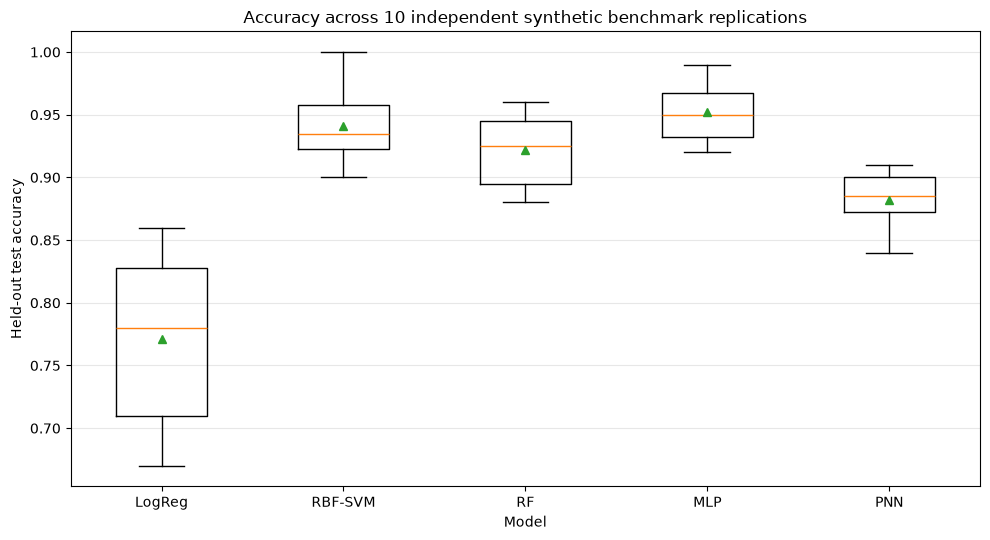

In [47]:
plot_order = [
    "Logistic regression 4D",
    "RBF-SVM 4D",
    "Random Forest 4D",
    "Small MLP 4D",
    "MZI-mesh-inspired PNN",
]

plot_values = [
    replication_accuracy_wide[
        model_name
    ].values
    for model_name in plot_order
]

plt.figure(
    figsize=(10, 5.5)
)

plt.boxplot(
    plot_values,
    tick_labels=[
        "LogReg",
        "RBF-SVM",
        "RF",
        "MLP",
        "PNN",
    ],
    showmeans=True
)

plt.ylabel(
    "Held-out test accuracy"
)

plt.xlabel(
    "Model"
)

plt.title(
    "Accuracy across 10 independent synthetic benchmark replications"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "mlst_independent_replication_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 30. Additional VQC architecture sensitivity analysis

The existing four-qubit model uses one ZZ-feature-map repetition and a shallow `ry` variational layer. To reduce the risk that the quantum result reflects only one circuit choice, this section adds a second, more expressive four-qubit configuration:

- ZZ feature map: 1 repetition;
- trainable rotations: `ry` and `rz`;
- variational repetitions: 2;
- linear CX entanglement.

The same test set is **not** used to choose the model. Random restarts are selected by the training objective exactly as in the primary VQC analysis.

## 30.1 Train the alternative 4-qubit VQC

In [48]:
ALT_VQC_SEED = SEED + 500

best_vqc4_alt, restarts4_alt = train_vqc_multistart(
    X_train=X_train4,
    y_train=y_train,
    num_qubits=4,
    feature_map_reps=1,
    ansatz_reps=2,
    rotation_blocks=["ry", "rz"],
    maxiter=1200,
    n_restarts=12,
    seed=ALT_VQC_SEED
)

display(
    restarts4_alt
)

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 00 | training loss=0.876465 | training accuracy=0.713


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 01 | training loss=0.862684 | training accuracy=0.690


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 02 | training loss=0.853320 | training accuracy=0.703


... (13 outputs left out)

restart 09 | training loss=0.860654 | training accuracy=0.710


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 10 | training loss=0.837787 | training accuracy=0.743
restart 11 | training loss=0.842624 | training accuracy=0.723

Selected restart using minimum training objective.
Best training loss: 0.8377873252627359


,restart,training_loss,training_accuracy
0,0,0.876465,0.713333
1,1,0.862684,0.690000
2,2,0.853320,0.703333
3,3,0.864264,0.686667
4,4,0.859498,0.700000
5,5,0.857421,0.686667
6,6,0.843754,0.720000
7,7,0.873939,0.693333
8,8,0.844494,0.710000
9,9,0.860654,0.710000


## 30.2 Exact ideal accuracy, 4096-shot stability, and circuit complexity

In [49]:
pred_vqc4_alt_ideal, prob_vqc4_alt_ideal = (
    exact_statevector_predict(
        best_vqc4_alt,
        X_test4
    )
)

alt_ideal_acc, alt_ci_low, alt_ci_high = (
    wilson_ci_from_predictions(
        y_test,
        pred_vqc4_alt_ideal
    )
)

print(
    f"Alternative 4-qubit VQC ideal accuracy: "
    f"{alt_ideal_acc:.3f}"
)

print(
    f"95% Wilson CI: "
    f"[{alt_ci_low:.3f}, {alt_ci_high:.3f}]"
)


alt_shot_table, alt_accs, alt_preds = shot_sweep(
    best_vqc4_alt,
    X_test4,
    y_test,
    shots_list=[4096],
    n_reps=N_SHOT_REPS,
    seed0=1
)

display(
    alt_shot_table
)


complexity4_alt = circuit_complexity(
    best_vqc4_alt
)

display(
    pd.DataFrame(
        [
            {
                "Model": "4-qubit VQC shallow",
                **complexity4,
            },
            {
                "Model": "4-qubit VQC alternative",
                **complexity4_alt,
            },
        ]
    )
)

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


Alternative 4-qubit VQC ideal accuracy: 0.560
95% Wilson CI: [0.462, 0.653]


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
No gradient function provided, creating a gradient function. If your Sampler

4096 shots | mean=0.566 | SD=0.010


,shots,mean_accuracy,std_accuracy
0,4096,0.566,0.009661


,Model,Flat depth,Flat CX,Transpiled depth,Transpiled CX
0,4-qubit VQC shallow,21,15,31,15
1,4-qubit VQC alternative,27,18,41,18


## 30.3 Statistical comparisons for the alternative VQC

In [50]:
vqc_architecture_mcnemar = pd.DataFrame(
    [
        exact_mcnemar(
            y_test,
            pred_vqc4_ideal,
            pred_vqc4_alt_ideal,
            "4-qubit VQC shallow",
            "4-qubit VQC alternative"
        ),
        exact_mcnemar(
            y_test,
            pred_vqc4_alt_ideal,
            pred_pnn_ideal,
            "4-qubit VQC alternative",
            "PNN 4-mode ideal"
        ),
    ]
)

display(
    vqc_architecture_mcnemar
)


vqc_architecture_summary = pd.DataFrame(
    [
        {
            "Model": "4-qubit VQC shallow",
            "Ideal accuracy": accuracy_score(
                y_test,
                pred_vqc4_ideal
            ),
            "4096-shot mean accuracy": np.mean(
                accs4[4096]
            ),
            "4096-shot SD": np.std(
                accs4[4096],
                ddof=1
            ),
            **complexity4,
        },
        {
            "Model": "4-qubit VQC alternative",
            "Ideal accuracy": alt_ideal_acc,
            "4096-shot mean accuracy": np.mean(
                alt_accs[4096]
            ),
            "4096-shot SD": np.std(
                alt_accs[4096],
                ddof=1
            ),
            **complexity4_alt,
        },
    ]
)

display(
    vqc_architecture_summary
)

4-qubit VQC shallow correct / 4-qubit VQC alternative wrong: 26
4-qubit VQC shallow wrong / 4-qubit VQC alternative correct: 21
Exact McNemar p-value: 0.560065
4-qubit VQC alternative correct / PNN 4-mode ideal wrong: 7
4-qubit VQC alternative wrong / PNN 4-mode ideal correct: 38
Exact McNemar p-value: 3.12131e-06


,Comparison,"A correct, B wrong","A wrong, B correct",p-value
0,4-qubit VQC shallow vs 4-qubit VQC alternative,26,21,0.560065
1,4-qubit VQC alternative vs PNN 4-mode ideal,7,38,0.000003


,Model,Ideal accuracy,4096-shot mean accuracy,4096-shot SD,Flat depth,Flat CX,Transpiled depth,Transpiled CX
0,4-qubit VQC shallow,0.61,0.610,1.170278e-16,21,15,31,15
1,4-qubit VQC alternative,0.56,0.566,9.660918e-03,27,18,41,18


# 31. Optional: repeated VQC validation

The most computationally expensive remaining validation is to retrain the VQCs on several independently generated benchmark datasets.

This is **optional in the notebook by default** because full multi-start VQC training can take a long time. For a final MLST submission, running this section on at least several independent replications would further strengthen the claim that the quantum results are not an artifact of one generated dataset.

Set:

```python
RUN_REPEATED_VQC_VALIDATION = True
```

when you are ready to run it.

The code uses the first five independent benchmark seeds and trains the original 2-qubit and shallow 4-qubit VQCs using the same primary training settings.

## 31.1 Optional VQC replication loop

In [53]:
RUN_REPEATED_VQC_VALIDATION = True

VQC_REPLICATION_SEEDS = (
    MLST_REPLICATION_SEEDS[:5]
)

vqc_replication_rows = []

if RUN_REPEATED_VQC_VALIDATION:

    for replication_number, rep_seed in enumerate(
        VQC_REPLICATION_SEEDS,
        start=1
    ):
        print(
            f"VQC replication {replication_number}/"
            f"{len(VQC_REPLICATION_SEEDS)} "
            f"(dataset seed={rep_seed})"
        )

        rep = prepare_ml_st_replication(
            dataset_seed=rep_seed,
            split_seed=rep_seed
        )

        Xtr4 = rep["X_train4"]
        Xte4 = rep["X_test4"]
        ytr = rep["y_train"]
        yte = rep["y_test"]

        # Use the first two coordinates of the same nested 4D representation.
        Xtr2 = Xtr4[:, :2]
        Xte2 = Xte4[:, :2]

        rep_vqc2, _ = train_vqc_multistart(
            X_train=Xtr2,
            y_train=ytr,
            num_qubits=2,
            feature_map_reps=2,
            ansatz_reps=4,
            rotation_blocks=["ry", "rz"],
            maxiter=600,
            n_restarts=8,
            seed=rep_seed
        )

        rep_vqc4, _ = train_vqc_multistart(
            X_train=Xtr4,
            y_train=ytr,
            num_qubits=4,
            feature_map_reps=1,
            ansatz_reps=1,
            rotation_blocks=["ry"],
            maxiter=1200,
            n_restarts=12,
            seed=rep_seed + 100
        )

        pred2, _ = exact_statevector_predict(
            rep_vqc2,
            Xte2
        )

        pred4, _ = exact_statevector_predict(
            rep_vqc4,
            Xte4
        )

        vqc_replication_rows.extend(
            [
                {
                    "Replication": replication_number,
                    "Dataset seed": rep_seed,
                    "Model": "2-qubit VQC",
                    "Ideal accuracy": accuracy_score(
                        yte,
                        pred2
                    ),
                },
                {
                    "Replication": replication_number,
                    "Dataset seed": rep_seed,
                    "Model": "4-qubit VQC shallow",
                    "Ideal accuracy": accuracy_score(
                        yte,
                        pred4
                    ),
                },
            ]
        )

    vqc_replication_metrics = pd.DataFrame(
        vqc_replication_rows
    )

    display(
        vqc_replication_metrics
    )

    vqc_replication_summary_rows = []

    for model_name, group in (
        vqc_replication_metrics.groupby(
            "Model"
        )
    ):
        mean, sd, low, high = replication_mean_ci(
            group["Ideal accuracy"]
        )

        vqc_replication_summary_rows.append(
            {
                "Model": model_name,
                "Mean ideal accuracy": mean,
                "SD": sd,
                "95% CI lower": low,
                "95% CI upper": high,
            }
        )

    vqc_replication_summary = pd.DataFrame(
        vqc_replication_summary_rows
    )

    display(
        vqc_replication_summary
    )

else:
    print(
        "Repeated VQC validation is OFF. "
        "Set RUN_REPEATED_VQC_VALIDATION = True "
        "when you are ready for the long-running quantum validation."
    )

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


VQC replication 1/5 (dataset seed=7)


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 00 | training loss=0.977146 | training accuracy=0.603


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 01 | training loss=0.981562 | training accuracy=0.600


... (192 outputs left out)

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


restart 10 | training loss=0.951611 | training accuracy=0.617
restart 11 | training loss=0.956567 | training accuracy=0.600

Selected restart using minimum training objective.
Best training loss: 0.9206386515188204


,Replication,Dataset seed,Model,Ideal accuracy
0,1,7,2-qubit VQC,0.63
1,1,7,4-qubit VQC shallow,0.62
2,2,17,2-qubit VQC,0.50
3,2,17,4-qubit VQC shallow,0.56
4,3,27,2-qubit VQC,0.52
5,3,27,4-qubit VQC shallow,0.66
6,4,37,2-qubit VQC,0.65
7,4,37,4-qubit VQC shallow,0.76
8,5,47,2-qubit VQC,0.60
9,5,47,4-qubit VQC shallow,0.63


,Model,Mean ideal accuracy,SD,95% CI lower,95% CI upper
0,2-qubit VQC,0.580,0.066708,0.497171,0.662829
1,4-qubit VQC shallow,0.646,0.073348,0.554926,0.737074


# 32. Save MLST-strengthening outputs

In [54]:
fixed_4d_performance.to_csv(
    "mlst_fixed_split_all_baselines.csv",
    index=False
)

strong_tuning_table.to_csv(
    "mlst_fixed_split_baseline_tuning.csv",
    index=False
)

fixed_mcnemar_vs_pnn.to_csv(
    "mlst_fixed_split_mcnemar_vs_pnn.csv",
    index=False
)

mlst_replication_metrics.to_csv(
    "mlst_independent_replication_metrics.csv",
    index=False
)

mlst_replication_summary.to_csv(
    "mlst_independent_replication_summary.csv",
    index=False
)

mlst_replication_hyperparameters.to_csv(
    "mlst_independent_replication_hyperparameters.csv",
    index=False
)

mlst_replication_pairwise.to_csv(
    "mlst_independent_replication_pairwise_tests.csv",
    index=False
)

vqc_architecture_mcnemar.to_csv(
    "mlst_vqc_architecture_mcnemar.csv",
    index=False
)

vqc_architecture_summary.to_csv(
    "mlst_vqc_architecture_summary.csv",
    index=False
)

if (
    "vqc_replication_metrics"
    in globals()
):
    vqc_replication_metrics.to_csv(
        "mlst_vqc_replication_metrics.csv",
        index=False
    )

if (
    "vqc_replication_summary"
    in globals()
):
    vqc_replication_summary.to_csv(
        "mlst_vqc_replication_summary.csv",
        index=False
    )

print(
    "Saved MLST-strengthening output tables."
)

Saved MLST-strengthening output tables.


# 33. Original and revised analyses

The tables produced above describe the original evaluation protocol. See \`revision/\` for the revised fold-local classical selection, matched quadratic controls, additional spectral descriptors, fresh 10,000-signal evaluation, tuned quantum encoding, and supplementary noise checks. Keep results from different protocols labeled separately.
